# Análise de séries temporais com Python
## Guia prático e progressivo para Engenharia de Computação

Este notebook apresenta um procedimento completo para analisar dados que possuem ordem temporal. O problema condutor é a telemetria de um servidor: registros horários de carga de CPU. O objetivo é compreender o comportamento do sistema, identificar problemas de qualidade, investigar padrões, detectar observações incomuns e avaliar previsões.

O material começa com Python básico e avança até modelos estatísticos e aprendizado de máquina. Todas as bases utilizadas são geradas no próprio notebook. Não é necessário baixar arquivos nem possuir conta em uma API. Os dados são **sintéticos**, criados para ensino; os resultados não representam medições de um servidor real.

**Como utilizar:** executar as células de cima para baixo. Uma célula de código depende das anteriores. No Google Colab, abrir este arquivo e selecionar *Ambiente de execução > Executar tudo*. No Jupyter ou VS Code, selecionar um ambiente Python e executar as células sequencialmente. Os gráficos e tabelas permanecem no arquivo quando ele é salvo depois da execução.

**Objetivos:** reconhecer estruturas temporais; preparar datas e valores; preservar a ordem do tempo; escolher uma frequência; distinguir exploração retrospectiva de previsão; construir referências simples; comparar modelos sem vazamento; interpretar erros e incerteza.

**Percurso:** ambiente e Python → problema e dados → auditoria → calendário → limpeza causal → exploração → componentes e dependência → validação temporal → referências → modelos → diagnóstico → previsão futura → sensores → adaptação e exercícios.

As primeiras seções são essenciais. ARIMA, SARIMA e aprendizado de máquina podem ser estudados em uma segunda etapa, após a compreensão das referências simples e da divisão temporal.

**No Google Colab:** selecionar Arquivo > Fazer upload de notebook e enviar este arquivo `.ipynb`; depois selecionar Ambiente de execução > Executar tudo. Os exemplos são executados em CPU, sem necessidade de GPU, Google Drive ou arquivos externos. Se a primeira célula atualizar um pacote já carregado, reiniciar a sessão e executar tudo novamente.

## 1. Preparar o ambiente

Uma biblioteca reúne funções prontas. `numpy` trabalha com números e vetores; `pandas` organiza tabelas e datas; `matplotlib` cria gráficos; `statsmodels` oferece modelos estatísticos; `scikit-learn` oferece modelos de aprendizado de máquina. A instalação é feita uma vez por ambiente. Se tudo já estiver instalado, a célula seguinte apenas verifica os pacotes. Uma instalação nova requer internet. Depois de instalar em um ambiente aberto, pode ser necessário reiniciar o kernel.

In [1]:
import importlib
import importlib.util
import importlib.metadata
import subprocess
import sys
import re
# Executar no Google Colab, Jupyter ou VS Code usando Python 3.10 ou posterior.
if sys.version_info < (3, 10):
    raise RuntimeError('Utilizar Python 3.10 ou posterior; o Colab fornece um ambiente compatível.')
pacotes = {
    'numpy': ('numpy', (1,24)), 'pandas': ('pandas', (2,1)),
    'matplotlib': ('matplotlib', (3,7)),
    'scipy': ('scipy', (1,11)), 'statsmodels': ('statsmodels', (0,14)),
    'sklearn': ('scikit-learn', (1,5))
}
instalar = []
for modulo, (distribuicao, minimo) in pacotes.items():
    if importlib.util.find_spec(modulo) is None:
        instalar.append(distribuicao + '>=' + '.'.join(map(str,minimo)))
    else:
        versao = tuple(int(v) for v in re.findall(r'\d+', importlib.metadata.version(distribuicao))[:2])
        if versao < minimo:
            instalar.append(distribuicao + '>=' + '.'.join(map(str,minimo)))
if instalar:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *instalar])
    print('Instalação concluída. Se um pacote já estava carregado, reiniciar a sessão e executar tudo novamente.')
else:
    print('Ambiente compatível: os pacotes necessários já estão disponíveis.')
# Mapeamento utilizado nas células seguintes.
pacotes = {modulo: distribuicao for modulo, (distribuicao, _) in pacotes.items()}


Ambiente compatível: os pacotes necessários já estão disponíveis.


**Como interpretar e qual é o próximo passo**

Se houver erro de instalação, conferir a conexão e o ambiente selecionado. O código utiliza o mesmo interpretador que executa o notebook, evitando instalar em outro Python.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import statsmodels
import sklearn
from IPython.display import display
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from pathlib import Path
import warnings
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True,
                     'grid.alpha': 0.25, 'font.size': 11})
pd.set_option('display.max_columns', 12)
print({p: importlib.import_module(p).__version__
       for p in ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels', 'sklearn']})

{'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'scipy': '1.17.0', 'statsmodels': '0.15.0', 'sklearn': '1.8.0'}


## 2. Primeiro contato com Python

Uma variável associa um nome a um valor. Uma lista contém vários elementos. Um índice identifica uma posição e começa em zero. `for` repete uma operação. `if` estabelece uma condição. Uma função, definida com `def`, permite reutilizar um procedimento. `return` devolve seu resultado. Não é necessário memorizar toda a linguagem antes de analisar os dados; é necessário reconhecer o papel de cada instrução.

In [3]:
leituras = [42.0, 45.0, 49.0, 46.0]
print('Primeira leitura:', leituras[0])
print('Quantidade:', len(leituras))
for leitura in leituras:
    if leitura >= 48:
        print('Leitura acima do limite ilustrativo:', leitura)
def media(valores):
    return sum(valores) / len(valores)
print('Média:', media(leituras))

Primeira leitura: 42.0
Quantidade: 4
Leitura acima do limite ilustrativo: 49.0
Média: 45.5


**Como interpretar e qual é o próximo passo**

Os valores são percentuais de CPU. O limite de 48% é apenas demonstrativo, não um critério operacional. Uma função evita repetir a mesma sequência de comandos.

## 3. Entender tabelas, vetores e seleção

Um `DataFrame` é uma tabela com linhas e colunas. Uma `Series` é uma sequência rotulada, como uma coluna da tabela. Vetores NumPy permitem operar com vários números ao mesmo tempo. Em pandas, `df["coluna"]` seleciona uma coluna, `.loc` seleciona por rótulos e `.iloc` seleciona por posições. `head()` mostra o início; `info()` mostra tipos e valores disponíveis.

In [4]:
exemplo = pd.DataFrame({'hora': [0, 1, 2, 3], 'cpu': leituras})
display(exemplo)
print('Coluna como vetor:', exemplo['cpu'].to_numpy())
display(exemplo.loc[exemplo['cpu'] > 44, ['hora', 'cpu']])
print('Segunda linha:')
display(exemplo.iloc[1])
exemplo.info()

Coluna como vetor: [42. 45. 49. 46.]
Segunda linha:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   hora    4 non-null      int64  
 1   cpu     4 non-null      float64
dtypes: float64(1), int64(1)
memory usage: 196.0 bytes


,hora,cpu
0,0,42.0
1,1,45.0
2,2,49.0
3,3,46.0


,hora,cpu
1,1,45.0
2,2,49.0
3,3,46.0


hora     1.0
cpu     45.0
Name: 1, dtype: float64

**Como interpretar e qual é o próximo passo**

Uma linha representa uma observação. Em séries temporais, cada linha também precisa indicar quando a observação ocorreu. Antes de modelar, é necessário conhecer unidades e tipos das colunas.

## 4. Formular o problema antes de programar

Uma série temporal é uma sequência de observações ordenadas no tempo: $y_t$, em que $t$ representa o instante. A dependência entre observações é central: a CPU atual pode estar relacionada à CPU da hora anterior e à rotina do mesmo horário em dias anteriores.

No exemplo principal, a variável é **CPU média por hora, em porcentagem**, e a frequência é horária. A tarefa de previsão é estimar **as próximas 24 horas de uma só vez**, usando somente informações disponíveis no instante da emissão. O horizonte de 24 horas é distinto de prever uma hora à frente e atualizar o modelo a cada nova medição.

Antes da coleta, registrar: variável e unidade; equipamento de origem; fuso horário; frequência esperada; período observado; horário de disponibilidade do dado; horizonte; ação associada à previsão; custo de cada tipo de erro. Uma CPU média horária pode esconder picos de segundos. Se a decisão for detectar sobrecarga instantânea, a frequência deste exemplo será insuficiente.

Em dados reais, verificar se o relógio representa o evento ou a chegada do registro. Em sistemas distribuídos, relógios desalinhados, atraso de rede e registros fora de ordem podem produzir padrões artificiais. Preservar os dados originais para auditoria.

## 5. Gerar uma base didática de telemetria

A simulação contém tendência lenta, padrão diário, padrão semanal e ruído. A semente fixa torna os resultados reproduzíveis. Serão inseridos problemas comuns: falhas de transmissão, valores não numéricos, duplicatas, datas inválidas e valores impossíveis. Uma base sem problemas não permitiria exercitar a preparação. A série completa conhecida fica separada e não será usada para preencher os dados observados nem para treinar modelos.

In [5]:
rng = np.random.default_rng(42)
datas = pd.date_range('2025-01-01', periods=24*120, freq='h', tz='UTC')
t = np.arange(len(datas))
diario = 12 * np.sin(2*np.pi*(datas.hour.to_numpy()-7)/24)
semanal = np.where(datas.dayofweek.to_numpy() < 5, 5, -5)
cpu = 43 + 0.003*t + diario + semanal + rng.normal(0, 2.5, len(t))
cpu[[400, 1100, 1700]] += 22
base_simulada = pd.DataFrame({'data': datas, 'cpu_pct': np.clip(cpu, 0, 100)})
bruto = base_simulada.copy()
bruto['data'] = bruto['data'].astype(str)
bruto['cpu_pct'] = bruto['cpu_pct'].astype(object)
bruto = bruto.drop(index=[60, 61, 62, 920, 1400])
bruto.loc[[150, 800], 'cpu_pct'] = np.nan
bruto.loc[210, 'cpu_pct'] = 'falha'
bruto.loc[300, 'cpu_pct'] = 145
bruto.loc[550, 'cpu_pct'] = -8
bruto.loc[750, 'data'] = 'data_invalida'
bruto = pd.concat([bruto, bruto.iloc[[100, 200]]], ignore_index=True)
bruto = bruto.sample(frac=1, random_state=42).reset_index(drop=True)
pasta = Path('saidas_series_temporais')
pasta.mkdir(exist_ok=True)
bruto.to_csv(pasta / 'telemetria_bruta.csv', index=False)
display(bruto.head())
print('Arquivo criado:', pasta / 'telemetria_bruta.csv')

Arquivo criado: saidas_series_temporais/telemetria_bruta.csv


,data,cpu_pct
0,2025-01-26 15:00:00+00:00,47.030718
1,2025-03-12 09:00:00+00:00,61.249642
2,2025-02-26 17:00:00+00:00,60.373779
3,2025-04-28 23:00:00+00:00,48.552378
4,2025-02-13 19:00:00+00:00,50.642829


**Como interpretar e qual é o próximo passo**

As linhas estão embaralhadas para demonstrar por que a ordem do arquivo não deve ser considerada a ordem temporal. O arquivo local será lido novamente na próxima etapa, reproduzindo o início de uma análise real.

## 6. Ler o CSV e auditar os tipos

`read_csv` lê um arquivo tabular. CSVs brasileiros podem utilizar `sep=";"` e `decimal=","`; esses parâmetros dependem do arquivo. `to_datetime` converte texto em data, e `to_numeric` converte texto em número. Com `errors="coerce"`, conversões impossíveis se tornam ausentes, permitindo contar os erros. Não se deve apagar silenciosamente essas ocorrências.

In [6]:
df = pd.read_csv(pasta / 'telemetria_bruta.csv')
df['data_original'] = df['data']
df['cpu_original'] = df['cpu_pct']
df['data'] = pd.to_datetime(df['data'], errors='coerce', utc=True)
df['cpu_pct'] = pd.to_numeric(df['cpu_pct'], errors='coerce')
print('Datas inválidas:', df['data'].isna().sum())
print('Valores ausentes ou inválidos:', df['cpu_pct'].isna().sum())
display(df.loc[df['data'].isna() | df['cpu_pct'].isna()].head(10))
df.info()

Datas inválidas: 1
Valores ausentes ou inválidos: 3
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2877 entries, 0 to 2876
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   data           2876 non-null   datetime64[ns, UTC]
 1   cpu_pct        2874 non-null   float64            
 2   data_original  2877 non-null   object             
 3   cpu_original   2875 non-null   object             
dtypes: datetime64[ns, UTC](1), float64(1), object(2)
memory usage: 90.0+ KB


,data,cpu_pct,data_original,cpu_original
1198,2025-01-09 18:00:00+00:00,NaN,2025-01-09 18:00:00+00:00,falha
1770,2025-01-07 06:00:00+00:00,NaN,2025-01-07 06:00:00+00:00,NaN
2572,2025-02-03 08:00:00+00:00,NaN,2025-02-03 08:00:00+00:00,NaN
2851,NaT,37.1728,data_invalida,37.17279968794638


**Como interpretar e qual é o próximo passo**

`NaT` indica data ausente; `NaN` indica número ausente. A conversão não corrige o registro, apenas torna o problema identificável. Para datas como 03/04/2025, definir explicitamente o formato para evitar confundir dia e mês.

## 7. Resolver datas inválidas, duplicatas e limites físicos

Sem data válida, o registro não pode ocupar uma posição no calendário; ele é preservado em uma tabela de rejeitados. Para duplicatas, primeiro investigar se representam retransmissões ou medições diferentes. Neste exemplo, são cópias idênticas, portanto basta manter uma. CPU inferior a 0% ou superior a 100% viola a definição usada. Esses números são marcados como ausentes, não simplesmente limitados a 0 ou 100, pois limitar mascararia uma falha de coleta.

In [7]:
rejeitados = df.loc[df['data'].isna()].copy()
df = df.loc[df['data'].notna()].copy()
print('Duplicatas de instante:', df.duplicated('data').sum())
display(df.loc[df.duplicated('data', keep=False)].sort_values('data'))
df = df.drop_duplicates(subset=['data'], keep='first').sort_values('data')
invalidos = ~df['cpu_pct'].between(0, 100) & df['cpu_pct'].notna()
print('Valores fisicamente impossíveis:', invalidos.sum())
df.loc[invalidos, 'cpu_pct'] = np.nan
serie_observada = df.set_index('data')['cpu_pct'].sort_index()
assert serie_observada.index.is_unique
assert serie_observada.index.is_monotonic_increasing
rejeitados.to_csv(pasta / 'registros_sem_data_valida.csv', index=False)
display(serie_observada.head())

Duplicatas de instante: 2
Valores fisicamente impossíveis: 2


,data,cpu_pct,data_original,cpu_original
121,2025-01-05 07:00:00+00:00,40.152789,2025-01-05 07:00:00+00:00,40.15278892116771
598,2025-01-05 07:00:00+00:00,40.152789,2025-01-05 07:00:00+00:00,40.15278892116771
244,2025-01-09 11:00:00+00:00,60.611152,2025-01-09 11:00:00+00:00,60.61115182860541
2766,2025-01-09 11:00:00+00:00,60.611152,2025-01-09 11:00:00+00:00,60.61115182860541


data
2025-01-01 00:00:00+00:00    37.170683
2025-01-01 01:00:00+00:00    33.403040
2025-01-01 02:00:00+00:00    38.291018
2025-01-01 03:00:00+00:00    39.968107
2025-01-01 04:00:00+00:00    34.649131
Name: cpu_pct, dtype: float64

**Como interpretar e qual é o próximo passo**

Em dados com várias máquinas, a chave deve incluir equipamento e instante. Duas máquinas no mesmo horário não são duplicatas. Médias entre duplicatas só fazem sentido se a semântica justificar essa agregação.

## 8. Construir o calendário e medir lacunas

Regularizar o calendário insere explicitamente os horários que deveriam existir. `asfreq("h")` não calcula médias: alinha a série a uma grade horária. Uma linha ausente no arquivo passa a ser um `NaN`. A quantidade de ausências inclui tanto falhas de coleta quanto números inválidos. A frequência deve ser escolhida a partir do processo, não apenas inferida automaticamente.

Frequência: h
Início: 2025-01-01 00:00:00+00:00 | Fim: 2025-04-30 23:00:00+00:00
Total esperado: 2880
Ausências: 11
Percentual ausente: 0.38
Maior lacuna consecutiva, em horas: 3


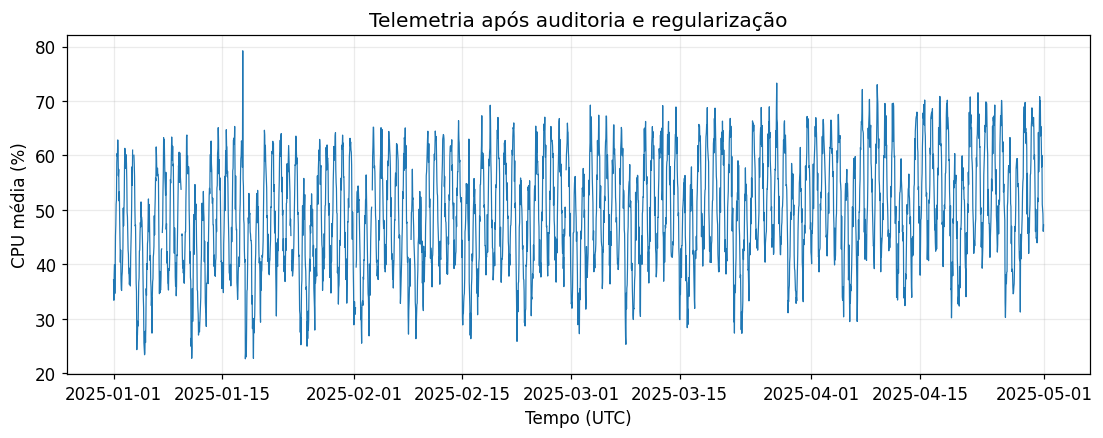

In [8]:
serie = serie_observada.asfreq('h')
print('Frequência:', serie.index.freqstr)
print('Início:', serie.index.min(), '| Fim:', serie.index.max())
print('Total esperado:', len(serie))
print('Ausências:', serie.isna().sum())
print('Percentual ausente:', round(100*serie.isna().mean(), 2))
bloco = serie.isna().ne(serie.isna().shift()).cumsum()
lacunas = serie.isna().groupby(bloco).sum()
print('Maior lacuna consecutiva, em horas:', int(lacunas.max()))
fig, ax = plt.subplots()
ax.plot(serie.index, serie, linewidth=0.8)
ax.set(title='Telemetria após auditoria e regularização', xlabel='Tempo (UTC)', ylabel='CPU média (%)')
plt.show()

**Como interpretar e qual é o próximo passo**

Uma linha visualmente contínua não prova ausência de lacunas. A contagem é necessária. Lacunas extensas exigem investigação e podem inviabilizar modelos que pressupõem espaçamento regular.

## 9. Entender fusos e agregação temporal

O armazenamento em UTC evita ambiguidade entre localidades. Para interpretar o comportamento humano, converter para o fuso do local do sistema. `tz_convert` muda a representação do mesmo instante. `tz_localize` associa um fuso a datas sem informação de fuso e exige cuidado com horários ambíguos ou inexistentes.

`resample` agrega intervalos. Para CPU percentual, uma média pode ser adequada se os intervalos de medição tiverem duração igual. Para energia consumida por intervalo, costuma-se somar. Para contador acumulado de bytes, calcular diferenças e tratar reinicializações antes de agregar. A operação depende da unidade.

Mesmo instante: 2025-01-01 00:00:00+00:00 → 2024-12-31 21:00:00-03:00


,mean,max,count,cobertura,media_com_cobertura
data,,,,,
2025-01-01 00:00:00+00:00,47.986956,62.857103,24,1.000,47.986956
2025-01-02 00:00:00+00:00,48.551342,61.319736,24,1.000,48.551342
2025-01-03 00:00:00+00:00,46.459714,60.990001,21,0.875,NaN
2025-01-04 00:00:00+00:00,37.854578,51.472431,24,1.000,37.854578
2025-01-05 00:00:00+00:00,37.796780,52.015880,24,1.000,37.796780


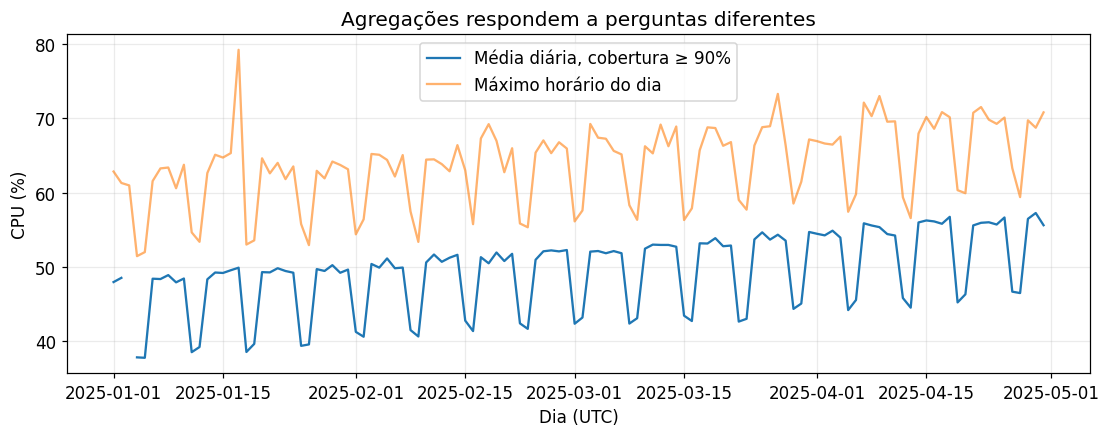

In [9]:
serie_local = serie.tz_convert('America/Sao_Paulo')
resumo_diario = serie.resample('D').agg(['mean', 'max', 'count'])
resumo_diario['cobertura'] = resumo_diario['count'] / 24
resumo_diario['media_com_cobertura'] = resumo_diario['mean'].where(resumo_diario['cobertura'] >= 0.9)
display(resumo_diario.head())
fig, ax = plt.subplots()
ax.plot(resumo_diario.index, resumo_diario['media_com_cobertura'], label='Média diária, cobertura ≥ 90%')
ax.plot(resumo_diario.index, resumo_diario['max'], alpha=0.6, label='Máximo horário do dia')
ax.set(xlabel='Dia (UTC)', ylabel='CPU (%)', title='Agregações respondem a perguntas diferentes')
ax.legend(); plt.show()
print('Mesmo instante:', serie.index[0], '→', serie_local.index[0])

**Como interpretar e qual é o próximo passo**

A cobertura evita interpretar uma média baseada em poucas leituras como representativa do dia inteiro. Em dias locais com alteração de horário, a quantidade esperada pode ser diferente de 24. Neste exemplo, os dias agregados são em UTC.

## 10. Separar passado e futuro antes de preencher

A divisão temporal impede treinar com dados posteriores à previsão. Serão reservados 14 dias finais para teste, 14 dias anteriores para validação e o restante para treinamento. A validação permite comparar candidatos; o teste permanece reservado até a escolha.

O preenchimento será causal: `ffill(limit=3)` usa somente o último valor conhecido e no máximo três horas consecutivas. Essa hipótese significa que a carga pode permanecer aproximadamente estável por um intervalo curto. Ela pode falhar em mudanças rápidas. Interpolação bidirecional usa pontos futuros e pode ser útil em exploração histórica, mas não reproduz a informação disponível em operação.

Tamanhos: 2208 336 336


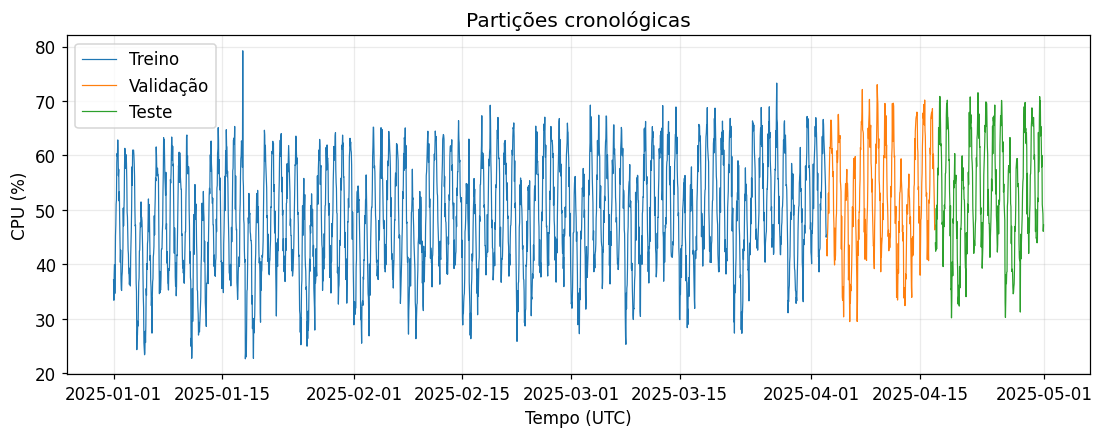

In [10]:
n_val = 24*14
n_teste = 24*14
corte_treino = len(serie) - n_val - n_teste
corte_teste = len(serie) - n_teste
# Preenchimento estritamente para a frente: nenhum dado posterior influencia o passado.
serie_modelo = serie.ffill(limit=3)
if serie_modelo.isna().any():
    raise ValueError('Restaram lacunas. Rever a coleta e a política de tratamento antes de continuar.')
treino = serie_modelo.iloc[:corte_treino]
validacao = serie_modelo.iloc[corte_treino:corte_teste]
teste = serie_modelo.iloc[corte_teste:]
# Os alvos de avaliação continuam sendo observações reais, sem valores imputados.
validacao_real = serie.iloc[corte_treino:corte_teste]
teste_real = serie.iloc[corte_teste:]
fig, ax = plt.subplots()
for nome, parte in [('Treino', treino), ('Validação', validacao), ('Teste', teste)]:
    ax.plot(parte.index, parte, label=nome, linewidth=0.8)
ax.set(title='Partições cronológicas', xlabel='Tempo (UTC)', ylabel='CPU (%)')
ax.legend(); plt.show()
print('Tamanhos:', len(treino), len(validacao), len(teste))

**Como interpretar e qual é o próximo passo**

O preenchimento pode atravessar a fronteira de uma partição porque o último dado anterior já é conhecido. Não utiliza o futuro. Os erros serão calculados somente onde há alvo observado. Não se deve premiar um modelo por prever valores artificialmente preenchidos.

## 11. Calcular estatísticas descritivas

Média, mediana, dispersão e quantis ajudam a entender magnitude e variabilidade. Essas medidas podem ser calculadas mesmo quando a distribuição não é normal. O que muda é a interpretação e a adequação de procedimentos inferenciais que pressupõem normalidade. Uma média global também pode esconder mudanças ao longo do tempo. A primeira exploração destinada à escolha de modelos deve utilizar apenas o treinamento.

,CPU (%)
count,2208.000000
mean,48.382888
std,10.095233
min,22.650239
5%,31.528875
25%,40.721848
50%,48.261990
75%,56.602650
95%,63.853560
max,79.236253


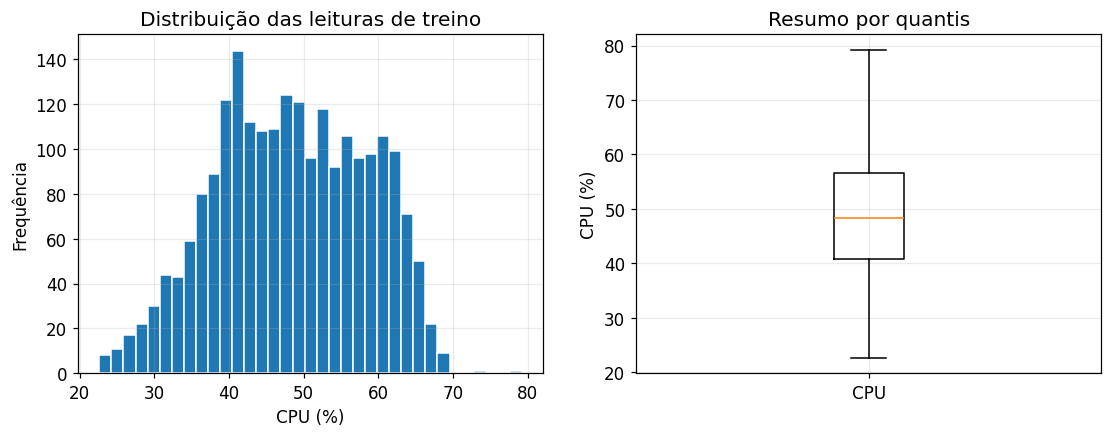

In [11]:
display(treino.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame('CPU (%)'))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(treino, bins=35, edgecolor='white')
axs[0].set(title='Distribuição das leituras de treino', xlabel='CPU (%)', ylabel='Frequência')
axs[1].boxplot(treino)
axs[1].set_xticks([1], ['CPU'])
axs[1].set(title='Resumo por quantis', ylabel='CPU (%)')
plt.show()

**Como interpretar e qual é o próximo passo**

O histograma ignora a ordem temporal. Duas séries com o mesmo histograma podem ter comportamentos totalmente diferentes no tempo. O boxplot identifica extremos relativos à distribuição, mas não considera padrões por hora.

## 12. Examinar tendência e janelas móveis

Uma janela móvel resume observações próximas. A média de 24 horas suaviza oscilações rápidas e ajuda a visualizar mudanças lentas. `rolling(24)` usa a observação atual e as 23 anteriores. Em uma previsão de $y_t$, a observação atual não está disponível e deve-se aplicar `shift(1)` antes de calcular a janela. Uma janela centralizada utiliza futuro e serve apenas à análise retrospectiva.

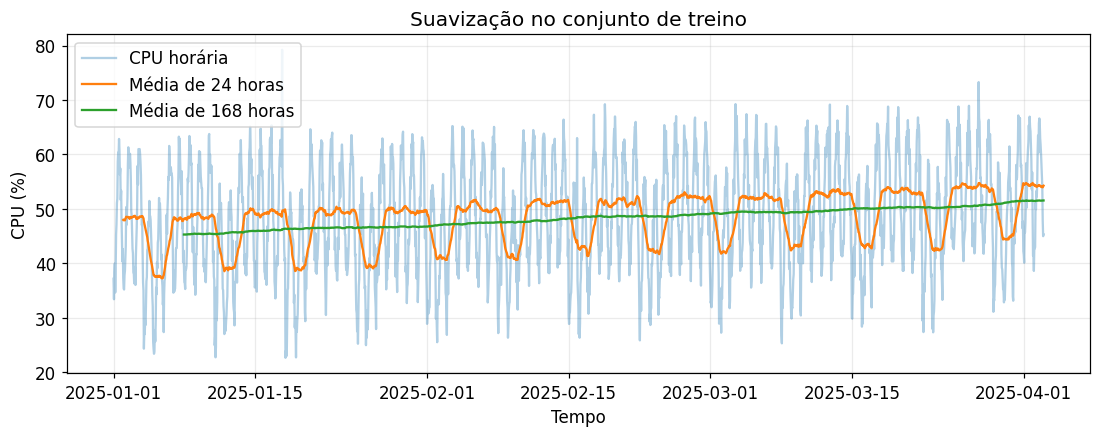

In [12]:
media_24 = treino.rolling(24, min_periods=24).mean()
media_168 = treino.rolling(168, min_periods=168).mean()
fig, ax = plt.subplots()
ax.plot(treino, alpha=0.35, label='CPU horária')
ax.plot(media_24, label='Média de 24 horas')
ax.plot(media_168, label='Média de 168 horas')
ax.set(title='Suavização no conjunto de treino', xlabel='Tempo', ylabel='CPU (%)')
ax.legend(); plt.show()

**Como interpretar e qual é o próximo passo**

Uma semana contém 168 horas. Janelas maiores suavizam mais, mas respondem mais lentamente a mudanças. Suavização não equivale automaticamente a previsão.

## 13. Investigar sazonalidade pelo calendário

Sazonalidade é um padrão que se repete em intervalos reconhecíveis, como horas do dia e dias da semana. Ciclos não precisam ter duração fixa. Tendência é uma alteração persistente de nível. Ruído é a variação que permanece não explicada pelo procedimento adotado.

O agrupamento por hora calcula um perfil médio. Esse perfil não prova causalidade: a carga pode acompanhar rotinas de usuários ou tarefas agendadas. Para o servidor simulado, o calendário de geração é UTC. Em um servidor real associado a usuários locais, utilizar o fuso desses usuários.

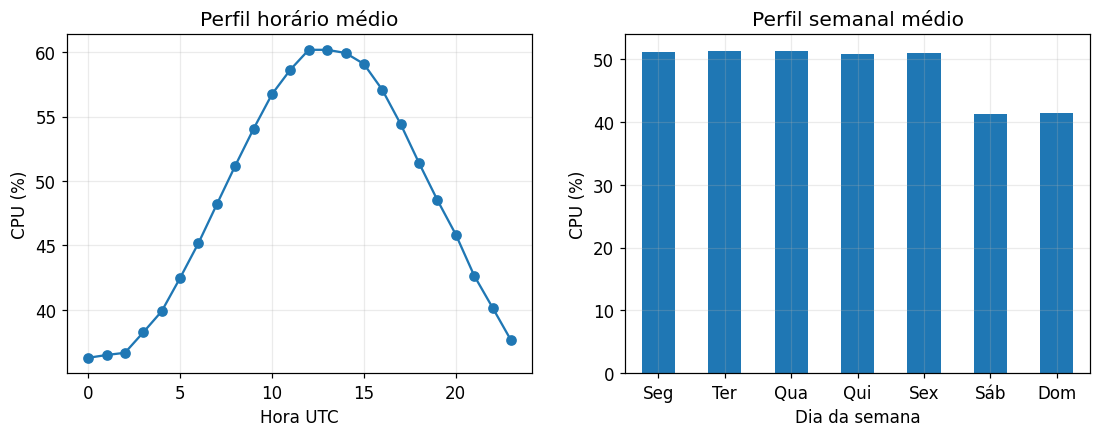

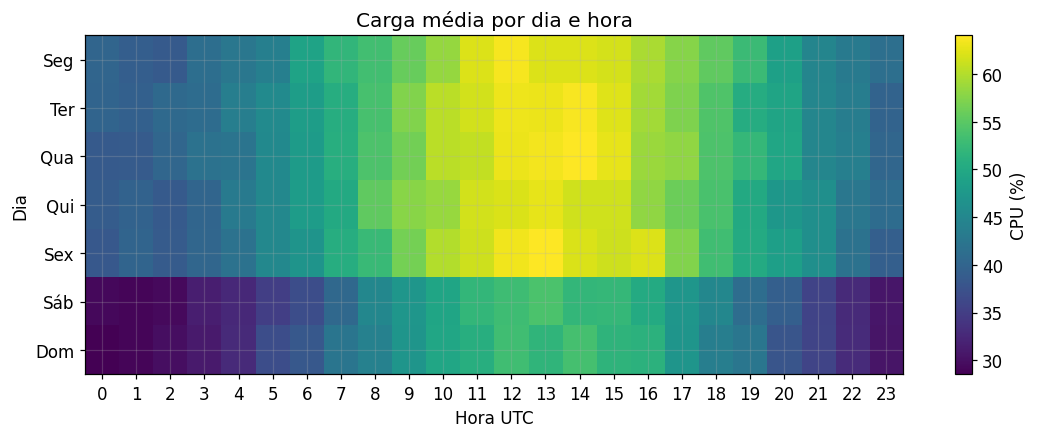

In [13]:
perfil = pd.DataFrame({'cpu': treino})
perfil['hora'] = perfil.index.hour
perfil['dia_semana'] = perfil.index.dayofweek
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
perfil.groupby('hora')['cpu'].mean().plot(marker='o', ax=axs[0])
axs[0].set(title='Perfil horário médio', xlabel='Hora UTC', ylabel='CPU (%)')
perfil.groupby('dia_semana')['cpu'].mean().plot(kind='bar', ax=axs[1])
axs[1].set_xticklabels(['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom'], rotation=0)
axs[1].set(title='Perfil semanal médio', xlabel='Dia da semana', ylabel='CPU (%)')
plt.show()
mapa = perfil.pivot_table(index='dia_semana', columns='hora', values='cpu', aggfunc='mean')
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(mapa, aspect='auto', cmap='viridis')
ax.set(xticks=range(24), yticks=range(7), yticklabels=['Seg','Ter','Qua','Qui','Sex','Sáb','Dom'],
       xlabel='Hora UTC', ylabel='Dia', title='Carga média por dia e hora')
fig.colorbar(im, ax=ax, label='CPU (%)'); plt.show()

**Como interpretar e qual é o próximo passo**

Se houver padrão semanal além do diário, um modelo com apenas período 24 pode deixar estrutura nos resíduos. Essa observação orienta candidatos, mas não dispensa validação fora do treinamento.

## 14. Decompor a série com STL

Na decomposição aditiva, $y_t = T_t + S_t + R_t$: tendência, sazonalidade e restante. Quando a amplitude sazonal cresce proporcionalmente ao nível, pode ser apropriada uma transformação logarítmica, desde que os dados sejam positivos e a justificativa faça sentido.

STL estima componentes suaves. Aqui, `period=24` informa um padrão diário e `robust=True` reduz a influência de extremos. O restante não é automaticamente um erro de medição. A decomposição é retrospectiva e usa informação dos dois lados de muitos pontos, portanto não deve ser aplicada à série completa para criar atributos de uma previsão histórica.

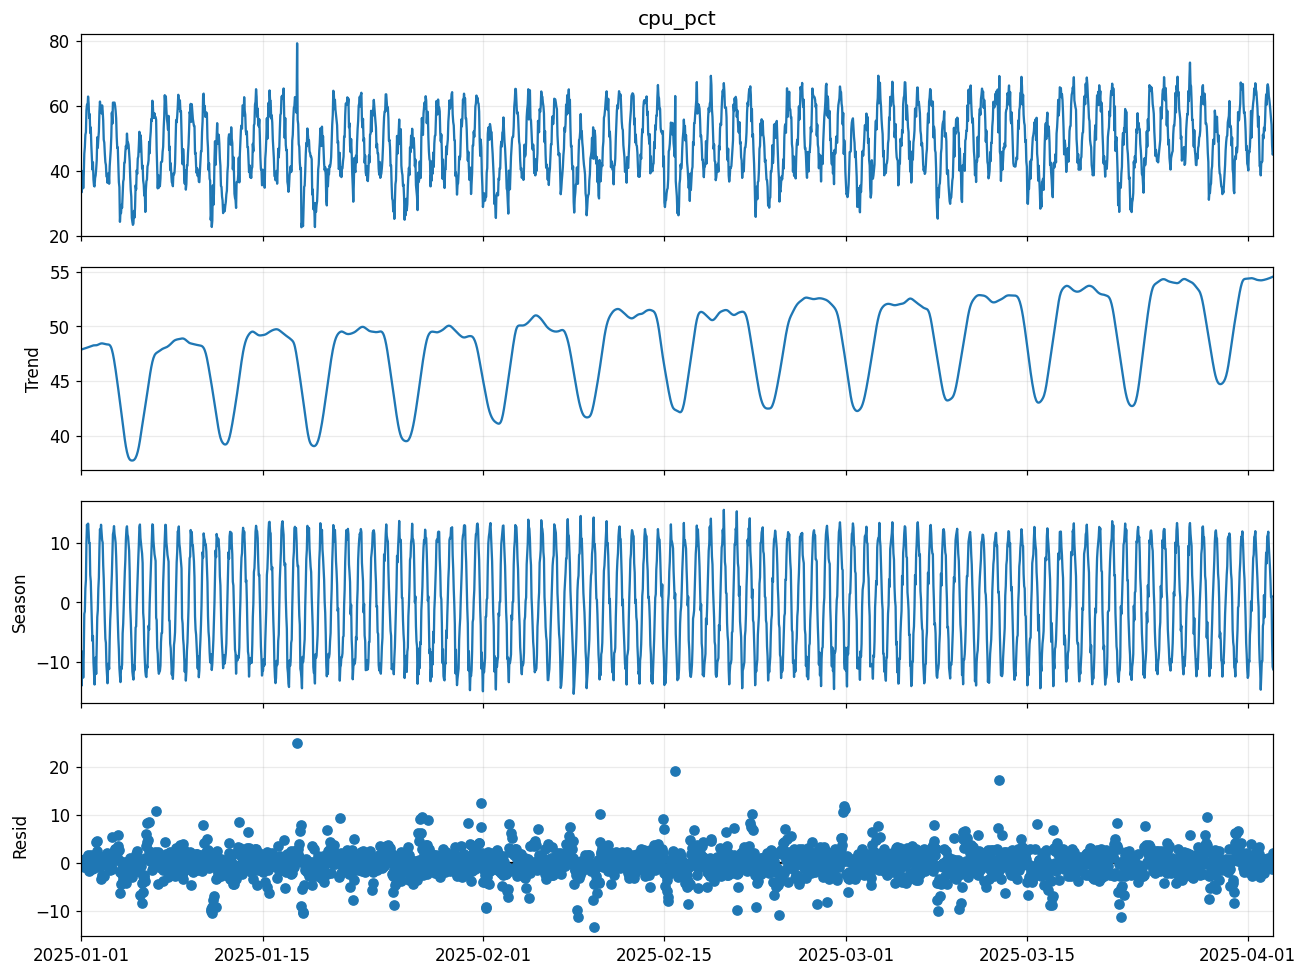

In [14]:
decomposicao = STL(treino, period=24, robust=True).fit()
fig = decomposicao.plot()
fig.set_size_inches(12, 9)
plt.tight_layout(); plt.show()

**Como interpretar e qual é o próximo passo**

O gráfico apresenta observado, tendência, sazonalidade e restante. Como há padrão semanal, parte dele pode continuar no restante ou na tendência. Um único período não representa todas as estruturas possíveis.

## 15. Entender defasagens e autocorrelação

Uma defasagem de uma hora associa $y_t$ a $y_{t-1}$. A autocorrelação mede associação linear entre a série e versões deslocadas dela. Picos nos múltiplos de 24 sugerem padrão diário. A PACF mede a associação em uma defasagem após controlar defasagens intermediárias, sendo útil na investigação de modelos autorregressivos.

As faixas dos gráficos são referências aproximadas sob hipóteses estatísticas. Muitos lags examinados aumentam a chance de picos ocasionais. ACF e PACF são instrumentos de diagnóstico, não regras suficientes para escolher automaticamente um modelo.

,atual,uma_hora_antes,um_dia_antes
data,,,
2025-01-01 00:00:00+00:00,37.170683,NaN,NaN
2025-01-01 01:00:00+00:00,33.403040,37.170683,NaN
2025-01-01 02:00:00+00:00,38.291018,33.403040,NaN
2025-01-01 03:00:00+00:00,39.968107,38.291018,NaN
2025-01-01 04:00:00+00:00,34.649131,39.968107,NaN
2025-01-01 05:00:00+00:00,38.759551,34.649131,NaN
2025-01-01 06:00:00+00:00,45.231772,38.759551,NaN
2025-01-01 07:00:00+00:00,47.230394,45.231772,NaN
2025-01-01 08:00:00+00:00,51.087826,47.230394,NaN


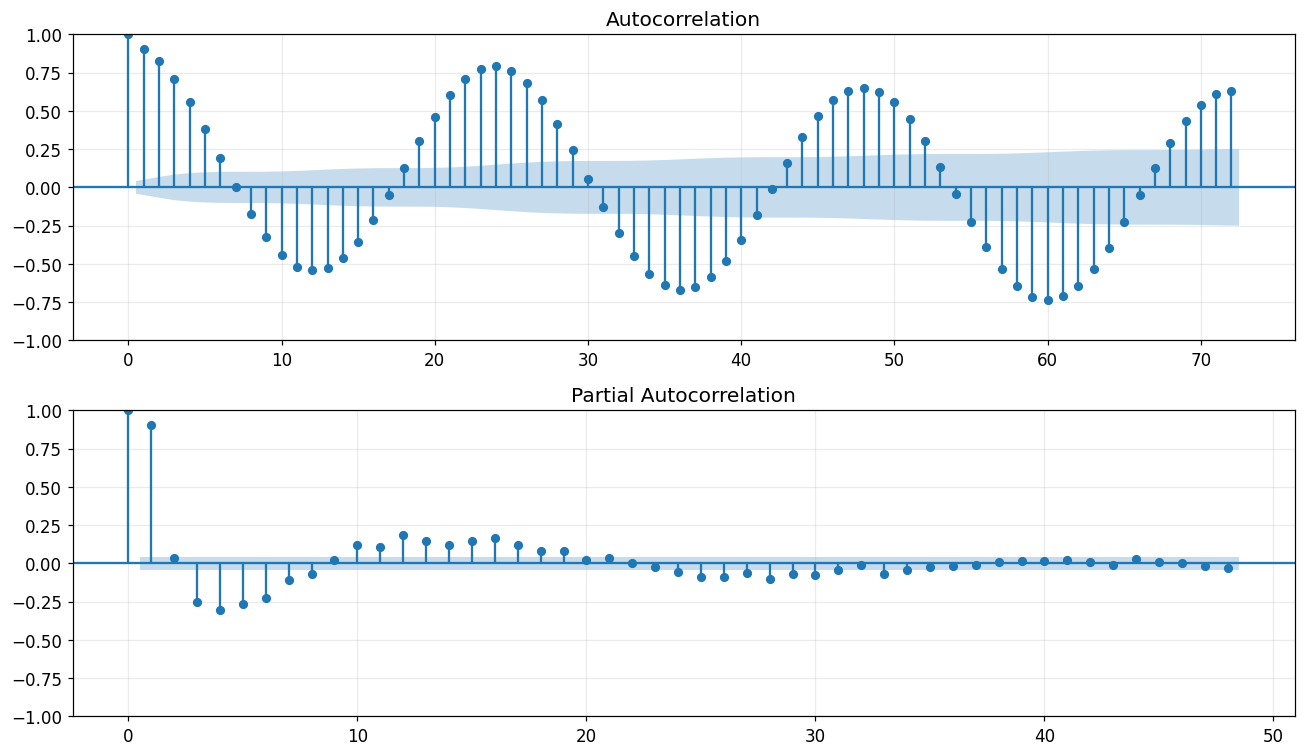

In [15]:
display(pd.DataFrame({'atual': treino, 'uma_hora_antes': treino.shift(1),
                      'um_dia_antes': treino.shift(24)}).head(27))
fig, axs = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(treino, lags=72, ax=axs[0])
plot_pacf(treino, lags=48, method='ywm', ax=axs[1])
plt.tight_layout(); plt.show()

**Como interpretar e qual é o próximo passo**

Correlação elevada não demonstra que uma leitura causa a seguinte. Ela indica dependência que pode ser útil para previsão. Tendência também pode produzir autocorrelações persistentes.

## 16. Estacionariedade, diferenças e testes

Estacionariedade fraca exige média e variância constantes e autocovariância dependente da distância temporal, não do instante. Não significa que todos os valores sejam iguais. Alguns modelos exigem uma série estacionária ou utilizam diferenças para reduzir tendência.

A primeira diferença é $\Delta y_t=y_t-y_{t-1}$. A diferença sazonal diária é $y_t-y_{t-24}$. Diferenciar em excesso pode aumentar o ruído e eliminar informação útil.

ADF possui hipótese nula de raiz unitária. Um p-valor pequeno fornece evidência contra essa hipótese, dentro da especificação utilizada. KPSS possui hipótese nula de estacionariedade, em torno de nível ou tendência conforme a opção. Nenhum teste comprova sozinho estacionariedade. Sazonalidade, quebras, tamanho da amostra e especificação afetam os resultados.

<ipython-input-1-4e9e141d77e6>:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(s.dropna(), regression='ct', autolag='AIC')
<ipython-input-1-4e9e141d77e6>:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(s.dropna(), regression='ct', autolag='AIC')
<ipython-input-1-4e9e141d77e6>:9: FutureWarning: adfuller currently returns a plain tuple whose 

,ADF_estatistica,ADF_p,KPSS_estatistica,KPSS_p,avisos_KPSS
original,-6.650398,0.0,0.013448,0.1,The test statistic is outside of the range of ...
diferença_1,-8.833426,0.0,0.017879,0.1,The test statistic is outside of the range of ...
diferença_24,-7.776402,0.0,0.009367,0.1,The test statistic is outside of the range of ...


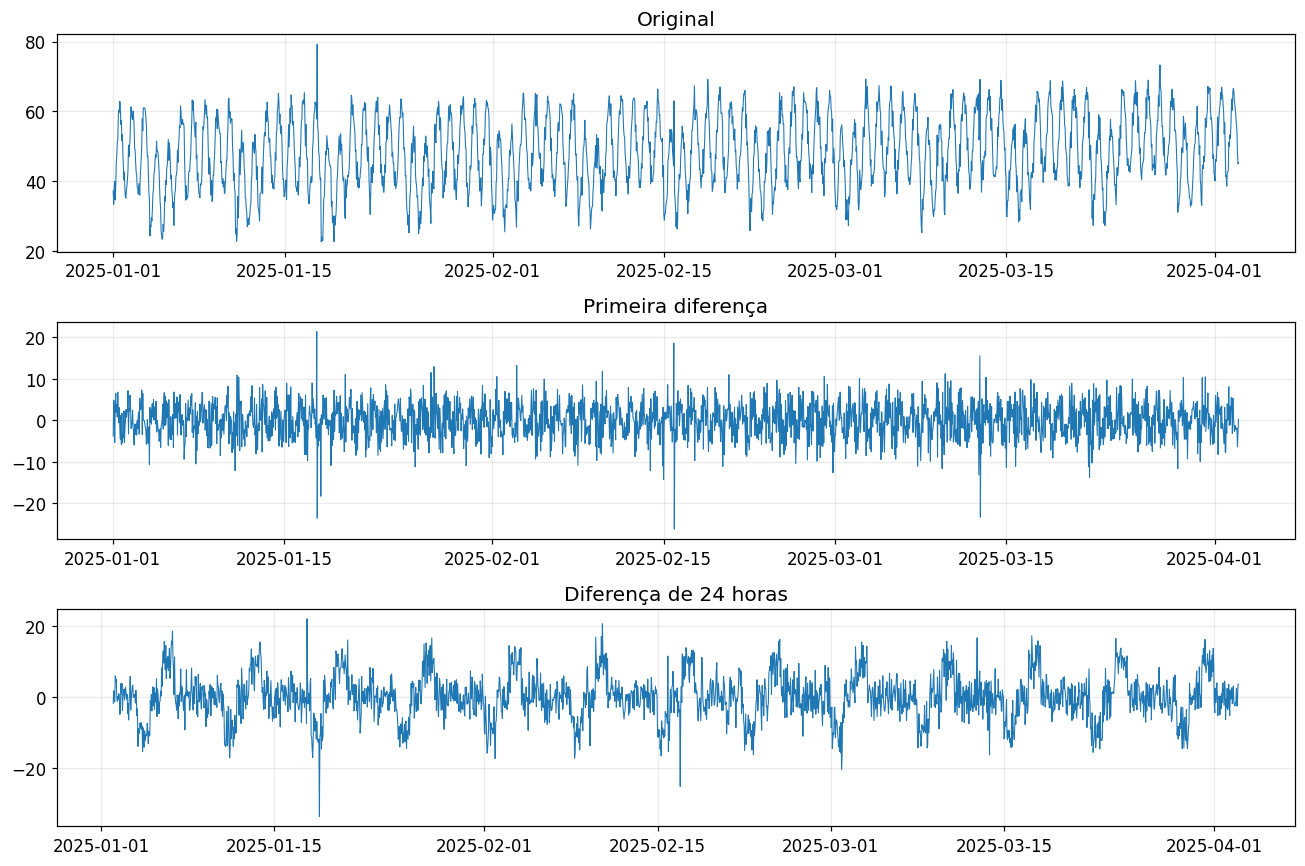

In [16]:
diferenca = treino.diff().dropna()
diferenca_diaria = treino.diff(24).dropna()
fig, axs = plt.subplots(3, 1, figsize=(12, 8))
for ax, valores, titulo in zip(axs, [treino, diferenca, diferenca_diaria],
                             ['Original', 'Primeira diferença', 'Diferença de 24 horas']):
    ax.plot(valores, linewidth=0.7); ax.set_title(titulo)
plt.tight_layout(); plt.show()
def testes_estacionariedade(s):
    adf = adfuller(s.dropna(), regression='ct', autolag='AIC')
    with warnings.catch_warnings(record=True) as avisos:
        resultado_kpss = kpss(s.dropna(), regression='ct', nlags='auto')
    return {'ADF_estatistica': adf[0], 'ADF_p': adf[1],
            'KPSS_estatistica': resultado_kpss[0], 'KPSS_p': resultado_kpss[1],
            'avisos_KPSS': '; '.join(str(a.message) for a in avisos)}
display(pd.DataFrame({nome: testes_estacionariedade(s)
    for nome, s in [('original', treino), ('diferença_1', diferenca),
                    ('diferença_24', diferenca_diaria)]}).T)

**Como interpretar e qual é o próximo passo**

A opção `ct` inclui constante e tendência determinística. Ela foi escolhida porque o exemplo contém tendência. Quando o teste avisa que o p-valor está fora da tabela, tratá-lo como limite, não como valor exato. Comparar gráficos e testes antes de decidir sobre diferenças.

## 17. Detectar candidatos a anomalias na análise histórica

Uma anomalia é uma observação incompatível com o comportamento esperado em um contexto. CPU de 70% pode ser normal no horário de pico e incomum durante a madrugada. Um detector baseado no restante da STL considera parte desse contexto.

A mediana e o desvio absoluto mediano (MAD) são menos sensíveis a extremos que média e desvio padrão. O escore robusto divide a distância à mediana por uma estimativa de escala. O limite 4 é ilustrativo. Um alerta deve ser investigado, não apagado automaticamente. Este detector é retrospectivo, não um sistema de detecção online.

,cpu,escore
data,,
2025-01-05 17:00:00+00:00,40.723855,-4.012787
2025-01-06 06:00:00+00:00,48.930429,4.026497
2025-01-06 19:00:00+00:00,55.701656,5.123033
2025-01-11 00:00:00+00:00,24.936738,-4.825247
2025-01-11 01:00:00+00:00,26.487344,-4.642153
2025-01-11 02:00:00+00:00,22.740569,-5.014154
2025-01-11 03:00:00+00:00,24.669082,-4.425083
2025-01-11 09:00:00+00:00,41.818083,-4.443827
2025-01-13 04:00:00+00:00,44.069449,4.009956


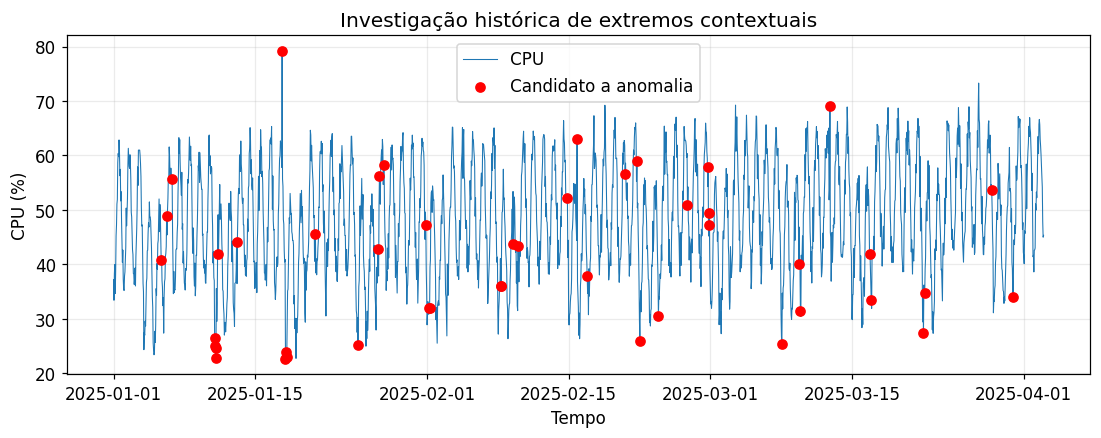

In [17]:
residuo_stl = decomposicao.resid
centro = residuo_stl.median()
mad = (residuo_stl - centro).abs().median()
escala = 1.4826 * mad
escore = (residuo_stl - centro) / max(escala, 1e-9)
alertas = escore.abs() > 4
fig, ax = plt.subplots()
ax.plot(treino, linewidth=0.7, label='CPU')
ax.scatter(treino.index[alertas], treino[alertas], color='red', label='Candidato a anomalia', zorder=3)
ax.set(title='Investigação histórica de extremos contextuais', xlabel='Tempo', ylabel='CPU (%)')
ax.legend(); plt.show()
display(pd.DataFrame({'cpu': treino[alertas], 'escore': escore[alertas]}).head(20))

**Como interpretar e qual é o próximo passo**

Consultar logs, processos, eventos de manutenção e integridade do sensor. Uma observação verdadeira de sobrecarga deve ser preservada. Remover eventos reais pode tornar a previsão aparentemente melhor e a operação menos segura.

## 18. Estabelecer o protocolo de previsão

O protocolo usado a seguir é **previsão de 24 horas em blocos**. No início de cada dia, utiliza-se todo o histórico disponível e emitem-se 24 previsões. Somente depois de avaliar esse bloco as observações dele entram no histórico. Isso simula uma atualização diária.

No aprendizado de máquina, as previsões dentro de cada bloco serão recursivas: após prever a primeira hora, o valor previsto será usado como defasagem para as horas seguintes. Inserir a CPU real de uma hora futura para prever outra hora do mesmo bloco mudaria a tarefa e produziria uma avaliação otimista.

No teste, as leituras anteriores do próprio teste podem entrar no histórico **após a data em que se tornam conhecidas**. Isso é permitido no protocolo de atualização diária. Não seria permitido para uma única previsão de 14 dias emitida no início.

Não usar `train_test_split` aleatório neste problema. Não ajustar escalas, limites estatísticos ou hiperparâmetros a partir do teste. Conhecer uma hora futura do calendário é permitido; conhecer sua CPU medida ainda não é.

## 19. Definir métricas e uma função de avaliação

O erro é $e_t=y_t-\hat y_t$. MAE é a média de $|e_t|$ e representa erro típico em pontos percentuais. RMSE é a raiz da média de $e_t^2$ e dá mais peso a erros grandes. Viés é a média de $\hat y_t-y_t$: valores positivos indicam superestimação.

MAPE divide o erro pelo valor observado e pode se tornar instável perto de zero. Por isso não será a métrica principal. A qualidade depende também do horizonte, do custo de subestimar picos e da comparação com uma referência simples. CPU de 50% prevista como 55% tem erro de 5 pontos percentuais, não de 5% relativo.

In [18]:
def metricas(real, previsto):
    real, previsto = real.align(previsto, join='inner')
    mascara = real.notna() & previsto.notna()
    r, p = real[mascara], previsto[mascara]
    if len(r) == 0:
        raise ValueError('Não existem pares válidos para avaliação.')
    return {'MAE_pp': mean_absolute_error(r, p),
            'RMSE_pp': np.sqrt(mean_squared_error(r, p)),
            'Vies_pp': float((p-r).mean()), 'N_observados': len(r)}
def avaliar_blocos(historico, futuro, funcao, horizonte=24):
    historico = historico.copy()
    partes = []
    for inicio in range(0, len(futuro), horizonte):
        bloco = futuro.iloc[inicio:inicio+horizonte]
        valores = np.asarray(funcao(historico, bloco.index), dtype=float).reshape(-1)
        if len(valores) != len(bloco):
            raise ValueError('O modelo devolveu quantidade incorreta de previsões.')
        partes.append(pd.Series(valores, index=bloco.index))
        historico = pd.concat([historico, bloco])
    return pd.concat(partes)
print('Funções de avaliação definidas.')

Funções de avaliação definidas.


**Como interpretar e qual é o próximo passo**

A função `avaliar_blocos` recebe um histórico, um período futuro e uma função de modelo. As ausências nos alvos originais são excluídas das métricas, sem avaliar dados imputados como se fossem medições.

## 20. Construir referências simples antes de modelos complexos

Persistência repete a última observação conhecida. Média recente repete a média das últimas 24 horas. Referência sazonal diária repete as mesmas horas do dia anterior. Referência semanal repete as horas equivalentes da semana anterior. Modelos complexos só se justificam se trouxerem benefício mensurável em relação a referências adequadas.

,MAE_pp,RMSE_pp,Vies_pp,N_observados
Sazonal 168h,3.009896,3.730663,-0.474278,336.0
Sazonal 24h,4.879248,6.481054,-0.134079,336.0
Média 24h,8.626055,10.380412,-0.134079,336.0
Persistência,12.897229,15.668646,-11.380818,336.0


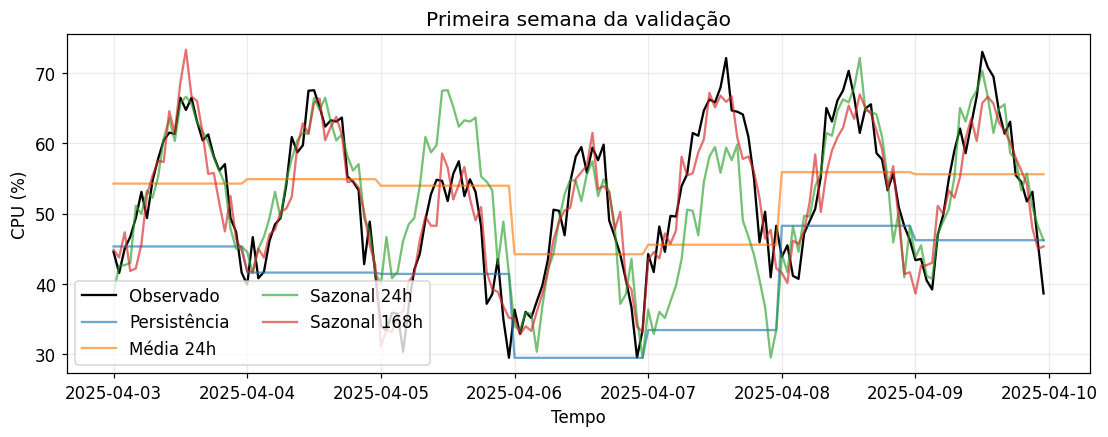

In [19]:
def persistencia(hist, indice):
    return np.repeat(hist.iloc[-1], len(indice))
def media_recente(hist, indice):
    return np.repeat(hist.iloc[-24:].mean(), len(indice))
def sazonal(hist, indice, periodo):
    return np.resize(hist.iloc[-periodo:].to_numpy(), len(indice))
def diaria(hist, indice):
    return sazonal(hist, indice, 24)
def semanal(hist, indice):
    return sazonal(hist, indice, 168)
modelos = {'Persistência': persistencia, 'Média 24h': media_recente,
           'Sazonal 24h': diaria, 'Sazonal 168h': semanal}
previsoes_val = {}
for nome, funcao in modelos.items():
    previsoes_val[nome] = avaliar_blocos(treino, validacao, funcao)
resultado_base = pd.DataFrame({nome: metricas(validacao_real, p)
                             for nome, p in previsoes_val.items()}).T.sort_values('MAE_pp')
display(resultado_base)
fig, ax = plt.subplots()
ax.plot(validacao_real.iloc[:168], color='black', label='Observado')
for nome, p in previsoes_val.items(): ax.plot(p.iloc[:168], alpha=0.65, label=nome)
ax.set(title='Primeira semana da validação', ylabel='CPU (%)', xlabel='Tempo')
ax.legend(ncol=2); plt.show()

**Como interpretar e qual é o próximo passo**

O padrão semanal pode ser útil porque o exemplo possui diferenças entre dias úteis e fins de semana. Isso não garante que a referência semanal seja melhor em outras aplicações.

## 21. Suavização exponencial e Holt-Winters

A suavização exponencial atribui pesos maiores a observações recentes. O parâmetro de nível controla a rapidez de adaptação. Holt acrescenta tendência; Holt-Winters acrescenta sazonalidade. Será usado nível, tendência aditiva amortecida e sazonalidade diária aditiva.

O amortecimento reduz a extrapolação indefinida da tendência. O modelo representa apenas um período sazonal explícito, portanto a sazonalidade semanal ainda pode permanecer nos erros. O ajuste usa uma janela de 28 dias para reduzir o tempo de execução e dar ênfase ao comportamento recente. Esse tamanho é uma escolha didática, não um valor universal.

In [20]:
def holt_winters(hist, indice):
    ajuste = ExponentialSmoothing(hist.iloc[-24*28:], trend='add', damped_trend=True,
                                 seasonal='add', seasonal_periods=24,
                                 initialization_method='estimated').fit(optimized=True)
    return ajuste.forecast(len(indice)).to_numpy()
modelos['Holt-Winters'] = holt_winters
previsoes_val['Holt-Winters'] = avaliar_blocos(treino, validacao, holt_winters)
display(pd.DataFrame([metricas(validacao_real, previsoes_val['Holt-Winters'])], index=['Holt-Winters']))

,MAE_pp,RMSE_pp,Vies_pp,N_observados
Holt-Winters,4.76239,6.480582,-0.143032,336


**Como interpretar e qual é o próximo passo**

Comparar com as referências usando as mesmas datas e o mesmo horizonte. Um modelo que acompanha bem a curva no treino pode falhar fora dele.

## 22. ARIMA: dependência, diferenças e erros passados

ARIMA combina três ideias. $p$ é a quantidade de termos autorregressivos, associados ao passado da série. $d$ é a ordem de diferenciação. $q$ é a quantidade de termos de média móvel do modelo, associados a erros passados. A média móvel de ARIMA não é a mesma operação que `rolling().mean()`.

O candidato ARIMA(2,1,1) será usado como exemplo restrito. Ele não representa explicitamente o padrão diário. Essa limitação é útil para comparar um modelo que descreve dependência local com modelos sazonais. A escolha de ordens não deve ser feita pelo teste final. Avisos de convergência precisam ser examinados.

In [21]:
def prever_arima(hist, indice):
    ajuste = ARIMA(hist.iloc[-24*28:], order=(2, 1, 1)).fit()
    if not ajuste.mle_retvals.get('converged', True):
        warnings.warn('ARIMA sem convergência: investigar antes de usar o resultado.')
    return ajuste.forecast(len(indice)).to_numpy()
modelos['ARIMA (2,1,1)'] = prever_arima
previsoes_val['ARIMA (2,1,1)'] = avaliar_blocos(treino, validacao, prever_arima)
display(pd.DataFrame([metricas(validacao_real, previsoes_val['ARIMA (2,1,1)'])], index=['ARIMA']))

/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py

,MAE_pp,RMSE_pp,Vies_pp,N_observados
ARIMA,16.585842,19.866744,-15.507204,336


**Como interpretar e qual é o próximo passo**

Não concluir que ARIMA é inadequado em geral a partir de um único candidato. O objetivo é entender seus componentes e medir o desempenho desta especificação no problema definido.

## 23. SARIMA e o período sazonal

SARIMA acrescenta termos sazonais: $(p,d,q)(P,D,Q)_s$. Em dados horários com padrão diário, $s=24$. O modelo didático usa um termo AR comum e um AR sazonal, com intercepto: $(1,0,0)(1,0,0)_{24}$.

A classe `SARIMAX` também permite regressoras externas. Elas só podem ser usadas em previsão se seus valores futuros estiverem disponíveis ou forem previstos separadamente. O nome da classe não obriga a utilizar regressoras. Aqui, não serão usadas. O candidato não descreve explicitamente todas as mudanças semanais ou tendências.

In [22]:
def prever_sarima(hist, indice):
    ajuste = SARIMAX(hist.iloc[-24*28:], order=(1,0,0), seasonal_order=(1,0,0,24),
                     trend='c', enforce_stationarity=True).fit(disp=False, maxiter=100)
    if not ajuste.mle_retvals.get('converged', True):
        warnings.warn('SARIMA sem convergência: investigar o ajuste.')
    return ajuste.forecast(len(indice)).to_numpy()
modelos['SARIMA diário'] = prever_sarima
previsoes_val['SARIMA diário'] = avaliar_blocos(treino, validacao, prever_sarima)
display(pd.DataFrame([metricas(validacao_real, previsoes_val['SARIMA diário'])], index=['SARIMA']))

/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  start_params = self.start_params
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  start_params = self.start_params


,MAE_pp,RMSE_pp,Vies_pp,N_observados
SARIMA,6.1846,7.634553,-2.510976,336


**Como interpretar e qual é o próximo passo**

Ordens sazonais elevadas podem tornar o ajuste lento. O período deve corresponder à frequência: 24 significa 24 amostras, não necessariamente 24 horas se a série tiver outra frequência.

## 24. Transformar série temporal em aprendizado supervisionado

No aprendizado supervisionado, cada linha possui atributos conhecidos e um alvo a prever. Serão usados lags de 1, 2, 24 e 168 horas, média das 24 horas anteriores, hora e dia da semana. A janela é deslocada antes do cálculo para excluir o alvo.

Hora será codificada por seno e cosseno, preservando a proximidade entre 23h e 0h. `RandomForestRegressor` combina árvores treinadas em subamostras. O modelo reconhece relações não lineares, mas árvores não extrapolam tendências como modelos lineares e não fornecem automaticamente intervalos de previsão confiáveis.

In [23]:
def tabela_atributos(s):
    x = pd.DataFrame(index=s.index)
    for lag in [1, 2, 24, 168]: x[f'lag_{lag}'] = s.shift(lag)
    x['media_24_passada'] = s.shift(1).rolling(24).mean()
    x['hora_sin'] = np.sin(2*np.pi*x.index.hour/24)
    x['hora_cos'] = np.cos(2*np.pi*x.index.hour/24)
    x['dia_semana'] = x.index.dayofweek
    x['alvo'] = s
    return x.dropna()
tabela_treino = tabela_atributos(treino)
colunas_x = tabela_treino.columns.drop('alvo').tolist()
display(tabela_treino.head())
print('Linhas utilizáveis:', len(tabela_treino))

Linhas utilizáveis: 2040


,lag_1,lag_2,lag_24,lag_168,media_24_passada,hora_sin,hora_cos,dia_semana,alvo
data,,,,,,,,,
2025-01-08 00:00:00+00:00,39.071073,42.341651,34.808537,37.170683,48.159742,0.000000,1.000000,2,36.521295
2025-01-08 01:00:00+00:00,36.521295,39.071073,35.396607,33.403040,48.231107,0.258819,0.965926,2,36.405094
2025-01-08 02:00:00+00:00,36.405094,36.521295,35.316648,38.291018,48.273128,0.500000,0.866025,2,35.281921
2025-01-08 03:00:00+00:00,35.281921,36.405094,37.696718,39.968107,48.271681,0.707107,0.707107,2,39.235876
2025-01-08 04:00:00+00:00,39.235876,35.281921,42.623669,34.649131,48.335812,0.866025,0.500000,2,38.893260


**Como interpretar e qual é o próximo passo**

As primeiras 168 observações não possuem todos os lags e são removidas da tabela de treinamento. O dia da semana é conhecido antecipadamente, ao contrário da carga futura.

## 25. Prever 24 horas recursivamente com Random Forest

O modelo aprende a prever uma hora com base em lags. Para emitir 24 horas de uma vez, é necessário atualizar o histórico com cada previsão, e não com a carga real ainda desconhecida. Os erros podem se acumular ao longo do horizonte. Uma alternativa é treinar modelos diretos separados por horizonte, mas isso exige outro desenho de atributos e treinamento.

O número de árvores será limitado para manter o notebook acessível. A profundidade e o tamanho mínimo das folhas restringem a complexidade. Os valores são candidatos didáticos e devem ser revisados na validação, sem usar o teste para ajuste.

In [24]:
def prever_floresta(hist, indice):
    tab = tabela_atributos(hist.iloc[-24*56:])
    modelo = RandomForestRegressor(n_estimators=80, max_depth=12,
                                  min_samples_leaf=3, random_state=42, n_jobs=-1)
    modelo.fit(tab[colunas_x], tab['alvo'])
    caminho = hist.copy()
    previsoes = []
    for instante in indice:
        linha = {f'lag_{lag}': caminho.iloc[-lag] for lag in [1, 2, 24, 168]}
        linha.update(media_24_passada=caminho.iloc[-24:].mean(),
                     hora_sin=np.sin(2*np.pi*instante.hour/24),
                     hora_cos=np.cos(2*np.pi*instante.hour/24), dia_semana=instante.dayofweek)
        entrada = pd.DataFrame([linha], columns=colunas_x)
        valor = float(modelo.predict(entrada)[0])
        previsoes.append(valor)
        caminho = pd.concat([caminho, pd.Series([valor], index=[instante])])
    return previsoes
modelos['Random Forest recursiva'] = prever_floresta
previsoes_val['Random Forest recursiva'] = avaliar_blocos(treino, validacao, prever_floresta)
display(pd.DataFrame([metricas(validacao_real, previsoes_val['Random Forest recursiva'])], index=['Random Forest']))

,MAE_pp,RMSE_pp,Vies_pp,N_observados
Random Forest,2.571721,3.133995,-0.802125,336


**Como interpretar e qual é o próximo passo**

O modelo é reajustado a cada dia, como os candidatos estatísticos. Uma comparação justa também precisa considerar tempo de treinamento, memória, simplicidade e capacidade de manutenção.

## 26. Visualizar validação temporal em várias janelas

Uma única fronteira de treino e validação pode depender muito de um período específico. Validação com origem móvel repete a análise em momentos sucessivos. `TimeSeriesSplit` organiza treino anterior e avaliação posterior. O gráfico mostra a geometria, não realiza automaticamente previsões.

Para uma previsão recursiva de 24 horas, utilizar a função de avaliação em blocos dentro de cada partição. Aplicar `predict` a atributos de toda uma semana contendo lags reais da própria semana avaliaria uma tarefa diferente. Quando a disponibilidade dos alvos ocorre com atraso, considerar uma separação `gap` adequada.

,janela,modelo,MAE_pp,RMSE_pp,Vies_pp,N_observados
0,1,Sazonal 24h,4.941323,6.354403,-0.159601,168
1,1,Sazonal 168h,3.120444,4.079582,-0.294992,168
2,2,Sazonal 24h,4.814108,6.416924,-0.129697,168
3,2,Sazonal 168h,3.009373,3.811643,-0.594737,168
4,3,Sazonal 24h,5.054745,6.501989,0.027556,168
5,3,Sazonal 168h,2.884318,3.617173,-0.189884,168
6,4,Sazonal 24h,4.554131,5.943159,-0.081603,168
7,4,Sazonal 168h,2.999908,3.780382,-1.048988,168


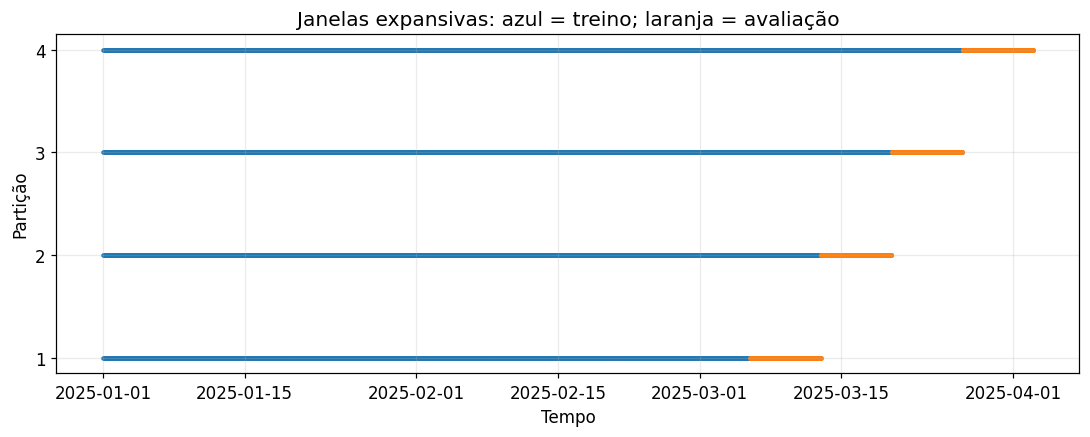

In [25]:
divisor = TimeSeriesSplit(n_splits=4, test_size=24*7)
fig, ax = plt.subplots(figsize=(12, 4))
for numero, (idx_tr, idx_va) in enumerate(divisor.split(treino), start=1):
    ax.scatter(treino.index[idx_tr], np.repeat(numero, len(idx_tr)), s=3, color='tab:blue')
    ax.scatter(treino.index[idx_va], np.repeat(numero, len(idx_va)), s=5, color='tab:orange')
ax.set(title='Janelas expansivas: azul = treino; laranja = avaliação', xlabel='Tempo', ylabel='Partição', yticks=[1,2,3,4])
plt.show()
resultados_janelas = []
for numero, (idx_tr, idx_va) in enumerate(divisor.split(treino), start=1):
    passado = treino.iloc[idx_tr]
    futuro = treino.iloc[idx_va]
    alvo = serie.reindex(futuro.index)
    for nome in ['Sazonal 24h', 'Sazonal 168h']:
        p = avaliar_blocos(passado, futuro, modelos[nome])
        resultados_janelas.append({'janela': numero, 'modelo': nome, **metricas(alvo, p)})
display(pd.DataFrame(resultados_janelas))

**Como interpretar e qual é o próximo passo**

As janelas verificam a estabilidade das referências no treinamento. Para seleção mais ampla, o mesmo procedimento pode ser aplicado aos demais candidatos, com maior custo computacional.

## 27. Comparar candidatos e escolher antes do teste

A seleção principal utilizará MAE na validação. RMSE e viés complementam a decisão. A ordenação é uma regra operacional explícita, não uma prova de superioridade estatística. Diferenças pequenas podem não justificar um modelo mais caro.

Neste notebook, o vencedor será escolhido automaticamente entre os candidatos já definidos. Após essa escolha, o teste será usado para estimar desempenho em um período posterior. Se o resultado do teste motivar novos ajustes, ele deixa de ser uma avaliação final independente e será necessário reservar um novo período.

Modelo escolhido pela validação: Random Forest recursiva


,MAE_pp,RMSE_pp,Vies_pp,N_observados
Random Forest recursiva,2.572,3.134,-0.802,336.0
Sazonal 168h,3.010,3.731,-0.474,336.0
Holt-Winters,4.762,6.481,-0.143,336.0
Sazonal 24h,4.879,6.481,-0.134,336.0
SARIMA diário,6.185,7.635,-2.511,336.0
Média 24h,8.626,10.380,-0.134,336.0
Persistência,12.897,15.669,-11.381,336.0
"ARIMA (2,1,1)",16.586,19.867,-15.507,336.0


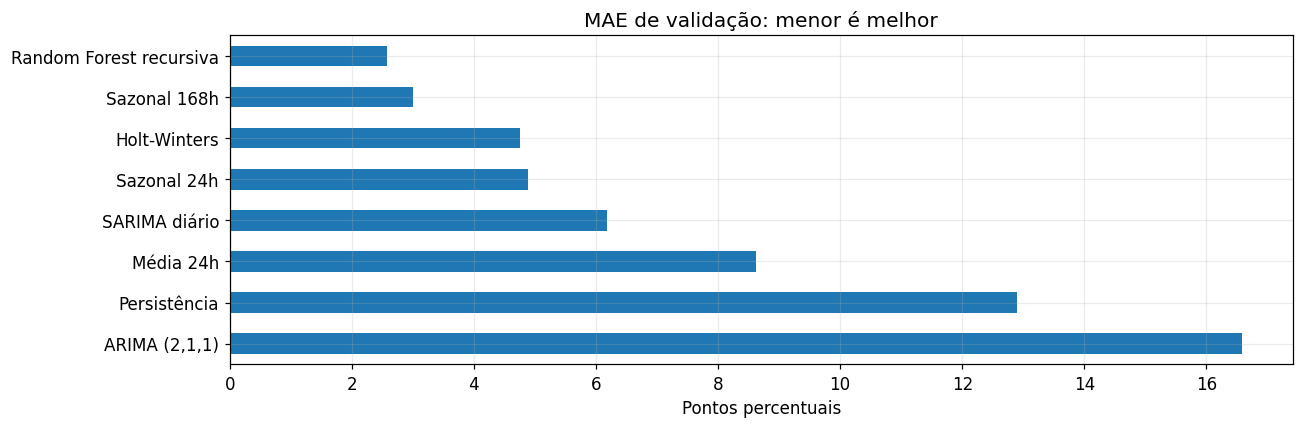

In [26]:
comparacao_val = pd.DataFrame({nome: metricas(validacao_real, p)
                              for nome, p in previsoes_val.items()}).T.sort_values('MAE_pp')
display(comparacao_val.round(3))
nome_escolhido = comparacao_val.index[0]
print('Modelo escolhido pela validação:', nome_escolhido)
fig, ax = plt.subplots()
comparacao_val['MAE_pp'].plot(kind='barh', ax=ax)
ax.invert_yaxis(); ax.set(title='MAE de validação: menor é melhor', xlabel='Pontos percentuais')
plt.tight_layout(); plt.show()

**Como interpretar e qual é o próximo passo**

Registrar candidatos, regra de seleção, janela de ajuste e protocolo de atualização. Isso permite reproduzir a escolha e detectar mudanças de comportamento posteriormente.

## 28. Avaliar o modelo escolhido no teste reservado

O histórico inicial do teste reúne treinamento e validação. O modelo escolhido e a referência semanal serão avaliados com o mesmo protocolo diário. A referência oferece um parâmetro de benefício prático. Não serão avaliados todos os candidatos para trocar o vencedor com base no teste.

,MAE_pp,RMSE_pp,Vies_pp,N_observados
Random Forest recursiva,2.410,3.094,-0.481,336.0
Referência semanal,2.885,3.623,-0.536,336.0


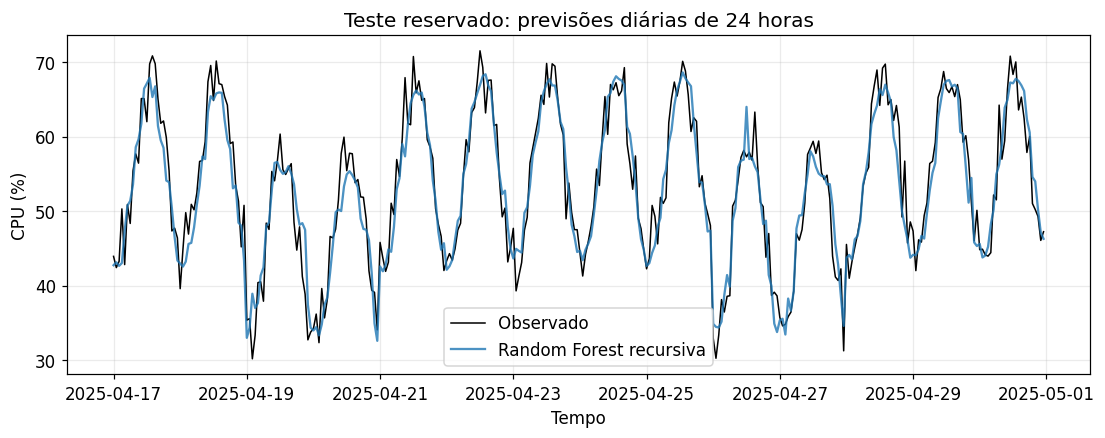

In [27]:
historico_teste = pd.concat([treino, validacao])
previsao_teste = avaliar_blocos(historico_teste, teste, modelos[nome_escolhido])
referencia_teste = avaliar_blocos(historico_teste, teste, semanal)
resultado_teste = pd.DataFrame({nome_escolhido: metricas(teste_real, previsao_teste),
                               'Referência semanal': metricas(teste_real, referencia_teste)}).T
display(resultado_teste.round(3))
fig, ax = plt.subplots()
ax.plot(teste_real, color='black', linewidth=1, label='Observado')
ax.plot(previsao_teste, alpha=0.8, label=nome_escolhido)
ax.set(title='Teste reservado: previsões diárias de 24 horas', xlabel='Tempo', ylabel='CPU (%)')
ax.legend(); plt.show()

**Como interpretar e qual é o próximo passo**

A simulação contém um processo relativamente estável. Um bom resultado não demonstra desempenho em produção ou em outro servidor. Testes com mudanças de regime e dados reais continuam necessários.

## 29. Examinar erros por horizonte e contexto

Um erro médio pode esconder desempenho pior nas últimas horas do horizonte ou nos fins de semana. O erro de previsão é observado fora da amostra; o resíduo de ajuste é calculado no conjunto usado para estimar o modelo. Não confundir os dois.

O gráfico por horizonte usa a posição de cada previsão dentro do bloco de 24 horas. O viés indica tendência sistemática a prever acima ou abaixo do observado. Para capacidade de servidores, subestimar carga de pico pode ter custo maior que superestimar carga moderada.

,mean,count
dia_semana,,
0,2.434417,48
1,2.016478,48
2,2.359161,48
3,2.388318,48
4,2.625573,48
5,2.761045,48
6,2.285885,48


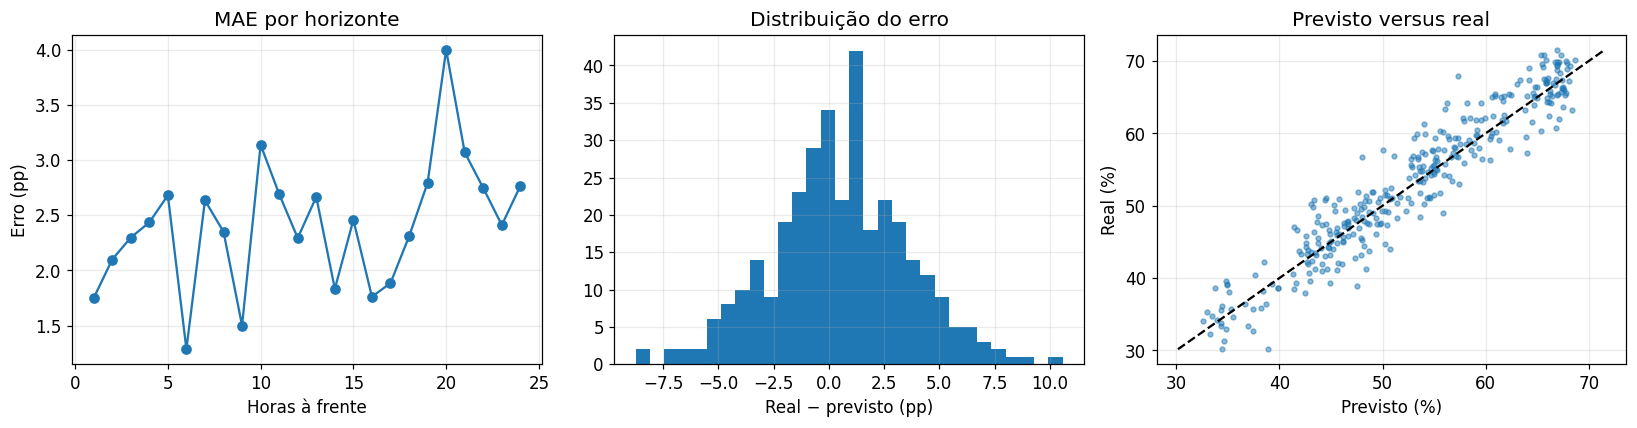

In [28]:
erros = pd.DataFrame({'real': teste_real, 'previsto': previsao_teste})
erros['erro'] = erros['real'] - erros['previsto']
erros['absoluto'] = erros['erro'].abs()
erros['horizonte'] = np.arange(len(erros)) % 24 + 1
erros['dia_semana'] = erros.index.dayofweek
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
erros.groupby('horizonte')['absoluto'].mean().plot(marker='o', ax=axs[0])
axs[0].set(title='MAE por horizonte', xlabel='Horas à frente', ylabel='Erro (pp)')
erros['erro'].hist(bins=30, ax=axs[1]); axs[1].set(title='Distribuição do erro', xlabel='Real − previsto (pp)')
axs[2].scatter(erros['previsto'], erros['real'], s=10, alpha=0.5)
limites = [erros[['real','previsto']].min().min(), erros[['real','previsto']].max().max()]
axs[2].plot(limites, limites, 'k--'); axs[2].set(title='Previsto versus real', xlabel='Previsto (%)', ylabel='Real (%)')
plt.tight_layout(); plt.show()
display(erros.groupby('dia_semana')['absoluto'].agg(['mean','count']))

**Como interpretar e qual é o próximo passo**

Se o erro aumenta com o horizonte, previsões recursivas podem estar acumulando incerteza. Se o erro depende do dia, pode faltar uma estrutura de calendário ou haver mudança operacional.

## 30. Investigar dependência nos erros

Um modelo que aproveita a estrutura temporal deve reduzir padrões previsíveis nos erros. A ACF dos erros e o teste Ljung-Box ajudam a investigar autocorrelação remanescente. A hipótese nula do teste é ausência de autocorrelação até as defasagens examinadas.

Como os erros são de previsões de vários horizontes e modelos reajustados por bloco, as hipóteses clássicas do teste podem não valer exatamente. O resultado será tratado como diagnóstico exploratório. Normalidade não é requisito universal de boa previsão. Distribuições e dependência dos erros importam especialmente para intervalos e inferência.

,lb_stat,lb_pvalue
24,42.816364,0.010438
48,97.787159,0.000029


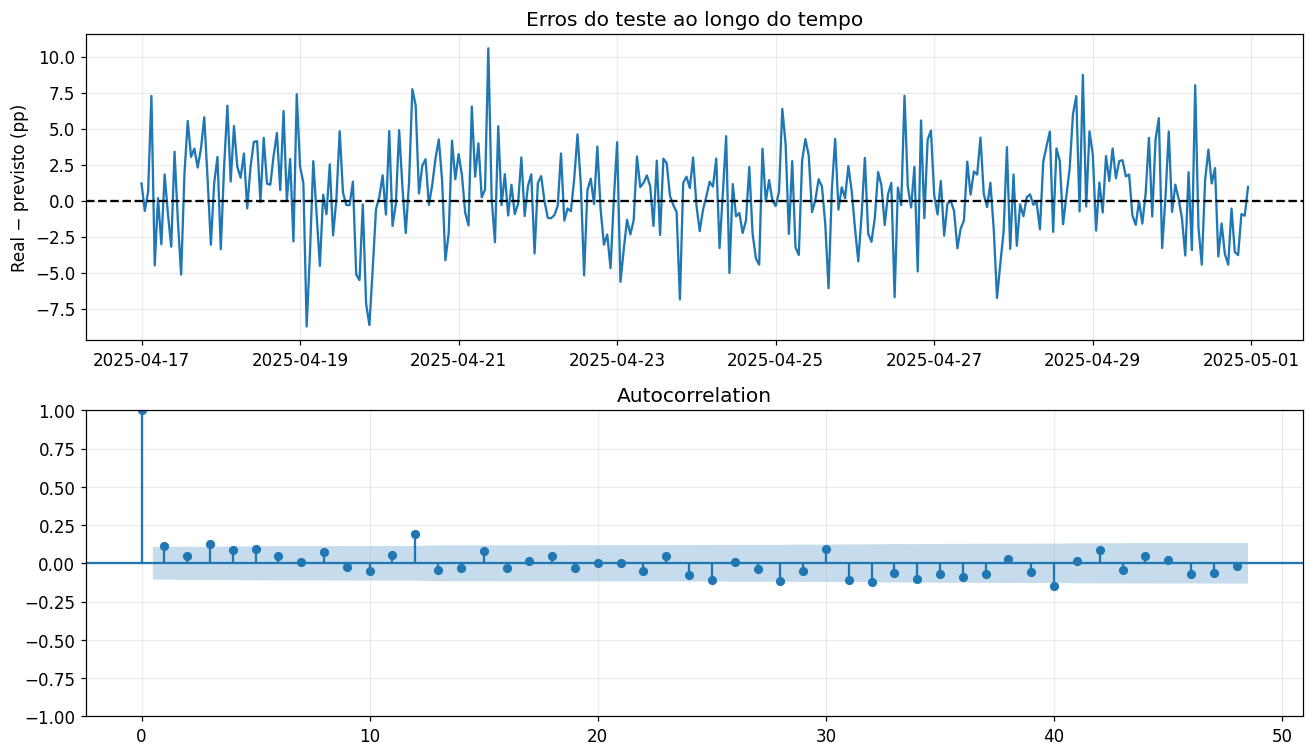

In [29]:
erro_valido = erros['erro'].dropna()
fig, axs = plt.subplots(2, 1, figsize=(12, 7))
axs[0].plot(erro_valido); axs[0].axhline(0, color='black', linestyle='--')
axs[0].set(title='Erros do teste ao longo do tempo', ylabel='Real − previsto (pp)')
plot_acf(erro_valido, lags=48, ax=axs[1]); plt.tight_layout(); plt.show()
display(acorr_ljungbox(erro_valido, lags=[24,48], return_df=True))

**Como interpretar e qual é o próximo passo**

Padrões nos erros sugerem estrutura ainda não representada. Ausência de autocorrelação significativa não comprova que o modelo está correto, nem que eventos raros serão previstos.

## 31. Compreender intervalos de previsão

Uma previsão pontual fornece um valor, mas não descreve a incerteza. Um intervalo de previsão procura representar a faixa de uma observação futura sob hipóteses do modelo. Ele difere de um intervalo de confiança de um parâmetro ou da média estimada.

Para demonstrar a API, será ajustado um SARIMA no histórico anterior ao teste e emitido um único bloco de 24 horas com intervalo nominal de 95%. Este modelo demonstrativo não substitui o vencedor da seleção. A cobertura nominal depende das hipóteses; não existe garantia de 95% de cobertura em qualquer base.

Cobertura observada neste bloco pequeno: 1.0


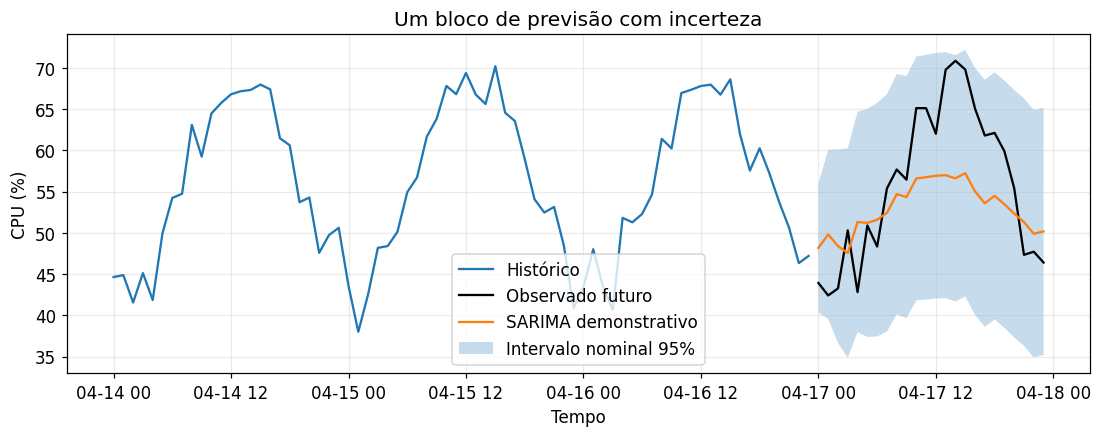

In [30]:
ajuste_intervalo = SARIMAX(historico_teste.iloc[-24*28:], order=(1,0,0),
                          seasonal_order=(1,0,0,24), trend='c').fit(disp=False, maxiter=100)
if not ajuste_intervalo.mle_retvals.get('converged', True):
    warnings.warn('Ajuste do intervalo sem convergência.')
objeto_previsao = ajuste_intervalo.get_forecast(steps=24)
media_prevista = objeto_previsao.predicted_mean
intervalo = objeto_previsao.conf_int(alpha=0.05)
fig, ax = plt.subplots()
ax.plot(historico_teste.iloc[-72:], label='Histórico')
ax.plot(teste_real.iloc[:24], label='Observado futuro', color='black')
ax.plot(media_prevista, label='SARIMA demonstrativo')
ax.fill_between(media_prevista.index, intervalo.iloc[:,0], intervalo.iloc[:,1], alpha=0.25, label='Intervalo nominal 95%')
ax.set(title='Um bloco de previsão com incerteza', xlabel='Tempo', ylabel='CPU (%)')
ax.legend(); plt.show()
alvo_bloco = teste_real.iloc[:24]
mask = alvo_bloco.notna()
cobertura = ((alvo_bloco >= intervalo.iloc[:,0]) & (alvo_bloco <= intervalo.iloc[:,1]))[mask].mean()
print('Cobertura observada neste bloco pequeno:', round(float(cobertura), 3))

**Como interpretar e qual é o próximo passo**

A cobertura de um único dia é muito instável. Avaliar cobertura e largura em muitos blocos históricos. Limites negativos ou acima de 100% podem indicar que uma distribuição sem limites físicos é inadequada; cortar limites altera a interpretação do intervalo.

## 32. Emitir a previsão realmente futura

Depois da seleção e da avaliação, o histórico completo observado até o presente pode ser usado para emitir uma nova previsão. Não há alvo disponível para esse período, portanto não há erro calculável ainda. A sequência temporal futura deve manter frequência e fuso da série.

Em produção, armazenar instante de emissão, horizonte, versão do modelo e previsão. Quando a medição correspondente chegar, calcular o erro. Esse registro evita misturar previsões emitidas antes e depois da observação.

,cpu_prevista_pct
2025-05-01 00:00:00+00:00,43.190756
2025-05-01 01:00:00+00:00,42.776798
2025-05-01 02:00:00+00:00,43.480751
2025-05-01 03:00:00+00:00,44.656856
2025-05-01 04:00:00+00:00,46.267281
2025-05-01 05:00:00+00:00,49.951866
2025-05-01 06:00:00+00:00,53.637181
2025-05-01 07:00:00+00:00,58.406017
2025-05-01 08:00:00+00:00,58.713402
2025-05-01 09:00:00+00:00,62.814950


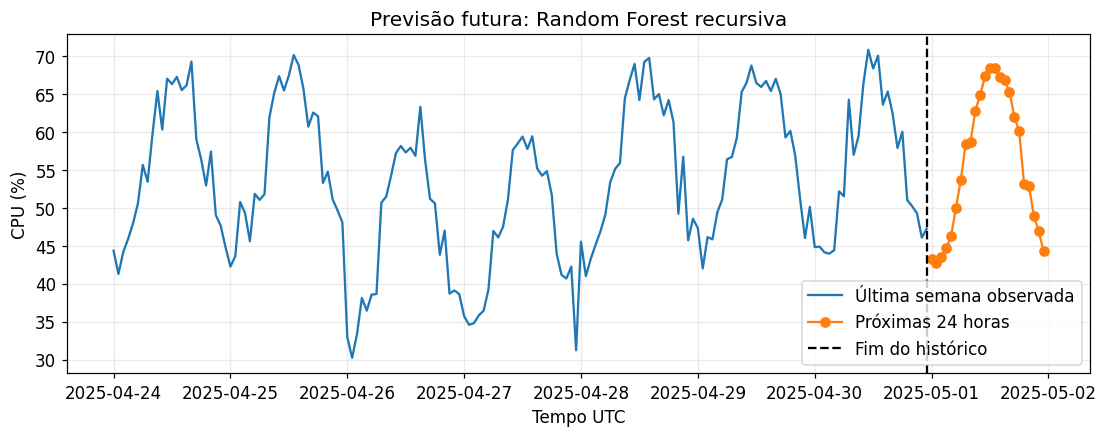

In [31]:
indice_futuro = pd.date_range(serie_modelo.index[-1] + pd.Timedelta(hours=1), periods=24, freq='h')
previsao_futura = pd.Series(modelos[nome_escolhido](serie_modelo, indice_futuro), index=indice_futuro, name='cpu_prevista_pct')
fig, ax = plt.subplots()
ax.plot(serie_modelo.iloc[-168:], label='Última semana observada')
ax.plot(previsao_futura, marker='o', label='Próximas 24 horas')
ax.axvline(serie_modelo.index[-1], color='black', linestyle='--', label='Fim do histórico')
ax.set(title=f'Previsão futura: {nome_escolhido}', xlabel='Tempo UTC', ylabel='CPU (%)')
ax.legend(); plt.show()
display(previsao_futura.to_frame())

**Como interpretar e qual é o próximo passo**

Se uma previsão estiver fora de limites físicos, investigar modelo e variável. Uma regra de pós-processamento deve ser definida previamente e avaliada com o mesmo protocolo, não acrescentada depois de observar o teste.

## 33. Exportar resultados e documentar o experimento

Uma análise reutilizável deve deixar rastros: base limpa, máscara de preenchimento, comparação na validação, avaliação final e previsões futuras. O notebook armazena código, teoria e resultados. CSVs permitem integrar a saída a outros sistemas.

A máscara diferencia uma medição de um valor estimado para preencher lacuna. Ela deve acompanhar a base limpa. Em um projeto real, incluir origem dos dados, permissões, unidade, frequência, política de limpeza e versões do ambiente.

In [32]:
pd.DataFrame({'cpu_observada_pct': serie, 'cpu_modelo_pct': serie_modelo,
              'foi_preenchido': serie.isna() & serie_modelo.notna()}).to_csv(pasta / 'telemetria_tratada.csv')
comparacao_val.to_csv(pasta / 'comparacao_validacao.csv')
resultado_teste.to_csv(pasta / 'avaliacao_teste.csv')
erros.to_csv(pasta / 'erros_teste.csv')
previsao_futura.to_csv(pasta / 'previsao_proximas_24h.csv')
print('Arquivos de resultados:')
for arquivo in sorted(pasta.glob('*.csv')): print(arquivo)
print('Semente: 42 | Frequência: horária | Horizonte: 24h | Atualização: diária')

Arquivos de resultados:
saidas_series_temporais/avaliacao_teste.csv
saidas_series_temporais/comparacao_validacao.csv
saidas_series_temporais/erros_teste.csv
saidas_series_temporais/previsao_proximas_24h.csv
saidas_series_temporais/registros_sem_data_valida.csv
saidas_series_temporais/telemetria_bruta.csv
saidas_series_temporais/telemetria_tratada.csv
Semente: 42 | Frequência: horária | Horizonte: 24h | Atualização: diária


**Como interpretar e qual é o próximo passo**

Esses arquivos são gerados no ambiente em que o notebook é executado. No Colab, o armazenamento da sessão é temporário; baixar os resultados desejados antes de encerrar a sessão.

## 34. Segundo contexto: sinal de sensor e frequência de amostragem

Telemetria horária e um sinal de sensor são séries temporais, mas respondem a perguntas diferentes. Em um sinal amostrado a $f_s$ amostras por segundo, uma oscilação de frequência $f$ precisa respeitar o critério de Nyquist: para evitar sobreposição espectral no caso ideal, $f<f_s/2$. Sistemas reais também precisam de filtragem anti-aliasing antes da aquisição.

A FFT transforma um trecho do sinal para o domínio de frequência. Picos indicam oscilações presentes, não causas físicas. A interpretação pressupõe amostragem regular. Uma janela de Hann reduz vazamento espectral, mas altera amplitudes e resolução. A demonstração usa frequências conhecidas de 5 e 17 Hz.

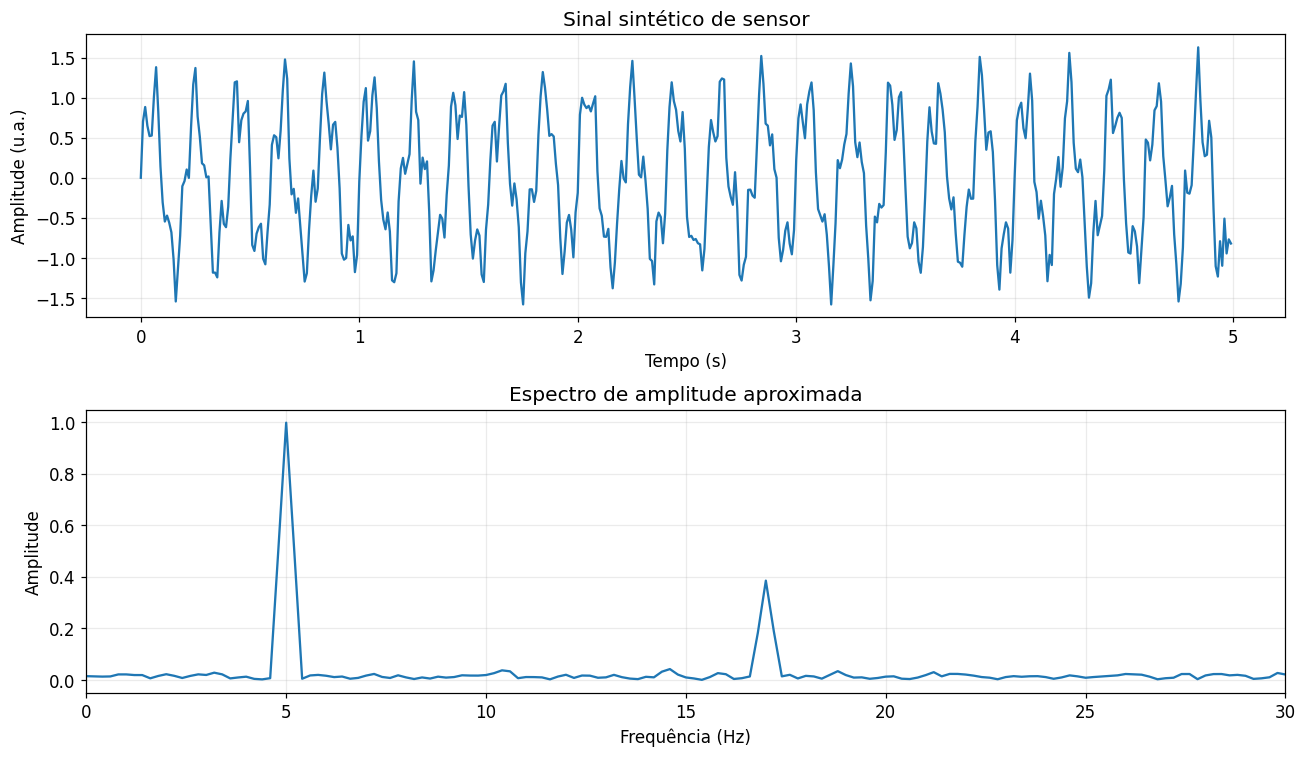

In [33]:
fs = 100
segundos = np.arange(0, 5, 1/fs)
rng_sensor = np.random.default_rng(7)
sinal = np.sin(2*np.pi*5*segundos) + 0.4*np.sin(2*np.pi*17*segundos) + rng_sensor.normal(0,0.15,len(segundos))
janela = np.hanning(len(sinal))
espectro = np.abs(np.fft.rfft((sinal-sinal.mean()) * janela)) * 2 / janela.sum()
frequencias = np.fft.rfftfreq(len(sinal), d=1/fs)
fig, axs = plt.subplots(2,1,figsize=(12,7))
axs[0].plot(segundos, sinal); axs[0].set(title='Sinal sintético de sensor', xlabel='Tempo (s)', ylabel='Amplitude (u.a.)')
axs[1].plot(frequencias, espectro); axs[1].set(title='Espectro de amplitude aproximada', xlabel='Frequência (Hz)', ylabel='Amplitude')
axs[1].set_xlim(0,30); plt.tight_layout(); plt.show()

**Como interpretar e qual é o próximo passo**

Os picos devem aparecer perto de 5 e 17 Hz. Frequência em Hz é ciclos por segundo; período 24 no modelo horário significa 24 amostras. Não confundir frequência de oscilação com frequência de coleta.

## 35. Demonstrar aliasing por subamostragem

Reduzir a quantidade de amostras sem filtragem pode fazer uma oscilação rápida parecer lenta. O exemplo retém uma amostra a cada dez, reduzindo a taxa de 100 para 10 Hz. O componente de 17 Hz fica acima do novo limite de Nyquist de 5 Hz e aparece em frequência incorreta. A demonstração não é um procedimento recomendado para redução de sinais.

Nova taxa: 10 amostras/s | Limite de Nyquist: 5 Hz


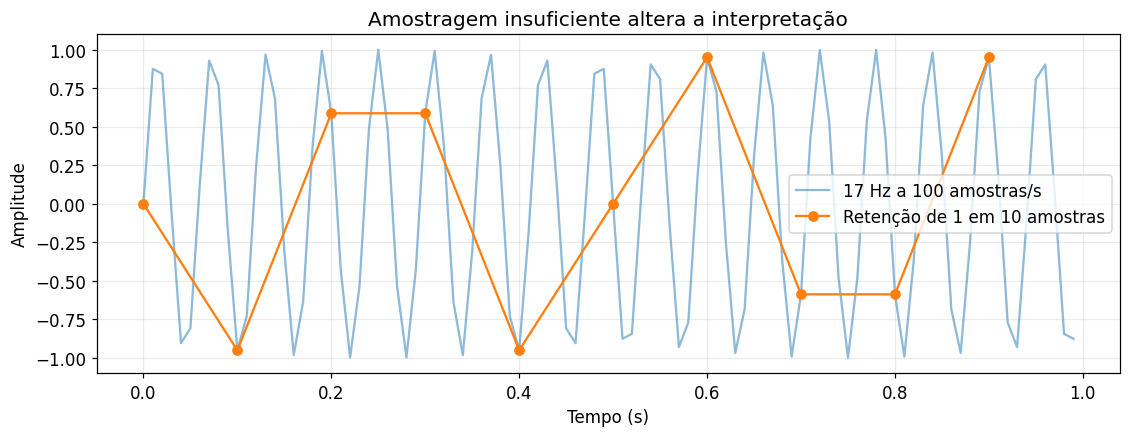

In [34]:
sinal_17 = np.sin(2*np.pi*17*segundos)
subtempo = segundos[::10]
subsinal = sinal_17[::10]
fig, ax = plt.subplots()
ax.plot(segundos[:100], sinal_17[:100], alpha=0.5, label='17 Hz a 100 amostras/s')
ax.plot(subtempo[:10], subsinal[:10], 'o-', label='Retenção de 1 em 10 amostras')
ax.set(title='Amostragem insuficiente altera a interpretação', xlabel='Tempo (s)', ylabel='Amplitude')
ax.legend(); plt.show()
print('Nova taxa: 10 amostras/s | Limite de Nyquist: 5 Hz')

**Como interpretar e qual é o próximo passo**

Médias horárias de telemetria também eliminam informação rápida, embora o problema não seja idêntico ao exemplo espectral. Definir a taxa de coleta a partir do fenômeno que se deseja observar.

## 36. Roteiro para adaptar a uma base própria

**Primeiro, definir a pergunta.** Descrever o equipamento, a variável, sua unidade, a frequência de coleta e a decisão esperada. Escolher se a tarefa é exploração histórica, detecção de eventos ou previsão. Em previsão, declarar o horizonte e quando o modelo será atualizado.

**Depois, preservar e ler os dados.** Manter o arquivo original. Verificar separador, codificação, nomes das colunas e convenção de datas. Converter datas e números explicitamente. Contar erros de conversão.

**Em seguida, auditar o tempo.** Conferir fuso, ordem, duplicatas e intervalo entre medições. Para vários equipamentos, analisar cada série separadamente ou construir um modelo que reconheça o identificador. Não conectar pontos de máquinas diferentes como se fossem uma única série.

**Construir a frequência adequada.** Decidir se os registros devem ser mantidos, agregados ou regularizados. A média serve para algumas grandezas, a soma para outras. Verificar cobertura de cada intervalo agregado.

**Separar cronologicamente.** Reservar treinamento, validação e teste. O teste deve representar o horizonte e o regime relevantes para a aplicação. Aplicar transformações causais e estimar parâmetros somente com dados disponíveis em cada instante.

**Tratar lacunas com justificativa.** Medir duração e causa. Escolher preenchimento limitado, modelo compatível com ausências ou exclusão de trechos conforme o problema. Nunca preencher o alvo futuro para facilitar a avaliação. Preservar uma coluna que indique imputações.

**Explorar o treinamento.** Examinar curva temporal, distribuição, janelas móveis e perfis de calendário. Investigar tendência, sazonalidade e mudanças de regime. Utilizar decomposição e testes como apoio, não como substitutos do conhecimento do sistema.

**Construir referências.** Implementar persistência, média recente e repetição sazonal quando aplicáveis. Medir erros no protocolo de previsão definido. Se a referência já atende à decisão, a complexidade adicional precisa de justificativa.

**Comparar modelos na validação.** Escolher candidatos compatíveis com o tamanho da base, frequência, sazonalidade e custo de manutenção. Usar métricas na unidade do problema e avaliar diferentes horizontes. Não escolher apenas pelo ajuste no treino.

**Avaliar uma vez no teste reservado.** Examinar MAE, RMSE, viés e padrões de erro. Registrar limitações. Se houver nova escolha motivada pelo teste, obter um novo período independente.

**Emitir e acompanhar previsões futuras.** Reajustar com o histórico permitido, salvar a emissão e comparar com medições quando chegarem. Monitorar falhas de coleta, alterações de padrão e degradação de desempenho. Reajustar não corrige automaticamente uma mudança de processo.

## 37. Modelo de importação de dados próprios

A célula seguinte é um exemplo deliberadamente desativado para que o notebook completo execute sem exigir outro arquivo. Alterar o caminho e os nomes apenas após conhecer a estrutura da base. Datas sem fuso precisam de uma decisão explícita sobre o fuso de origem. O exemplo supõe datas já contendo informação de fuso ou UTC.

In [35]:
USAR_ARQUIVO_PROPRIO = False
if USAR_ARQUIVO_PROPRIO:
    caminho = 'meus_dados.csv'
    dados_proprios = pd.read_csv(caminho, sep=',', decimal='.')
    dados_proprios['data'] = pd.to_datetime(dados_proprios['data'], errors='coerce', utc=True)
    dados_proprios['valor'] = pd.to_numeric(dados_proprios['valor'], errors='coerce')
    display(dados_proprios.head())
    print('Datas inválidas:', dados_proprios['data'].isna().sum())
    print('Valores ausentes:', dados_proprios['valor'].isna().sum())
    # Retomar a auditoria antes de regularizar, preencher ou modelar.
else:
    print('Exemplo desativado. O estudo principal utiliza telemetria sintética.')

Exemplo desativado. O estudo principal utiliza telemetria sintética.


## 38. Erros comuns e como reconhecê-los

| Situação | Consequência | Procedimento adequado |
|---|---|---|
| Datas mantidas como texto | Ordem alfabética pode substituir a cronológica | Converter e conferir exemplos |
| Divisão aleatória | Futuro pode orientar uma previsão do passado | Separar por tempo |
| Interpolar toda a base usando pontos futuros | Informação indisponível entra na avaliação | Usar política causal no experimento preditivo |
| Usar média móvel incluindo o alvo | A resposta participa dos atributos | Deslocar antes de calcular a janela |
| Prever 24h usando lags reais internos do bloco | A tarefa vira uma sequência com atualização horária | Recursão ou modelos diretos por horizonte |
| Avaliar alvos preenchidos | O erro descreve uma imputação, não uma medição | Avaliar somente observações reais |
| Remover todo pico | Eventos reais desaparecem da análise | Investigar contexto e registros |
| Escolher modelo pelo teste | O teste deixa de ser independente | Escolher na validação |
| Trocar unidade ou frequência sem registrar | Modelos recebem dados incompatíveis | Manter contrato de dados |
| Confundir ajuste com previsão | Curva bem ajustada parece desempenho futuro | Medir fora da amostra |
| Somar percentuais de CPU | Resultado perde interpretação física | Agregar conforme a grandeza |
| Tratar p-valor como certeza | Diagnóstico estatístico é superinterpretado | Explicitar hipóteses e limites |
| Acreditar que normalidade é necessária para calcular média | Medidas descritivas úteis são descartadas | Separar descrição de hipóteses inferenciais |
| Esperar que um intervalo nominal sempre cubra 95% | Incerteza fica subestimada | Medir cobertura histórica e largura |

Se aparecer `NameError`, provavelmente uma célula anterior não foi executada. Se aparecer `FileNotFoundError`, conferir o caminho e o diretório de execução. Um aviso de convergência exige revisar o ajuste, as ordens, a escala e a quantidade de dados. Não ocultar avisos indiscriminadamente.

## 39. Exercícios progressivos

1. Identificar variável, unidade, frequência e horizonte no exemplo principal. Explicar por que previsão de 24 horas em bloco difere de 24 previsões sucessivas atualizadas com medições reais.
2. Alterar a semente da simulação e executar o notebook novamente. Verificar se a ordenação dos modelos permanece igual e explicar por que pode mudar.
3. Inserir uma lacuna de 12 horas. Identificar onde o fluxo interrompe e propor uma política justificada sem utilizar medições posteriores à emissão.
4. Agregar CPU em intervalos de seis horas. Recalcular quantas amostras representam um dia e uma semana. Explicar quais estruturas deixam de ser visíveis.
5. Comparar média e mediana por hora. Investigar quais horários são mais influenciados pelos extremos inseridos.
6. Remover o componente semanal da simulação. Verificar como muda o desempenho da referência de 168 horas.
7. Alterar o horizonte para 48 horas. Ajustar a avaliação e observar como se comporta a previsão recursiva. Manter a regra de seleção e uma nova partição reservada.
8. Adicionar uma mudança permanente de nível perto do fim do histórico. Discutir o efeito nas referências e nos modelos com janela limitada.
9. Investigar erro nos horários de maior CPU. Propor uma métrica adicional coerente com o custo de subestimar a carga, sem modificar o teste já utilizado.
10. Substituir CPU por temperatura de um dispositivo. Definir limites físicos próprios e explicar por que não se deve reutilizar o intervalo de 0 a 100 automaticamente.
11. Reduzir a taxa de amostragem do sensor. Calcular o novo limite de Nyquist e identificar componentes que deixam de ser representados corretamente.
12. Preparar uma análise de dados próprios seguindo o roteiro. Entregar problema, auditoria, política de lacunas, divisão temporal, referências, comparação, diagnóstico e limitações.

As células seguintes oferecem espaço de trabalho. Executar o material original antes de modificar o experimento. Alterações no processo gerador ou no horizonte podem exigir revisar frequências, janelas e referências.

Quantidade de leituras: 73


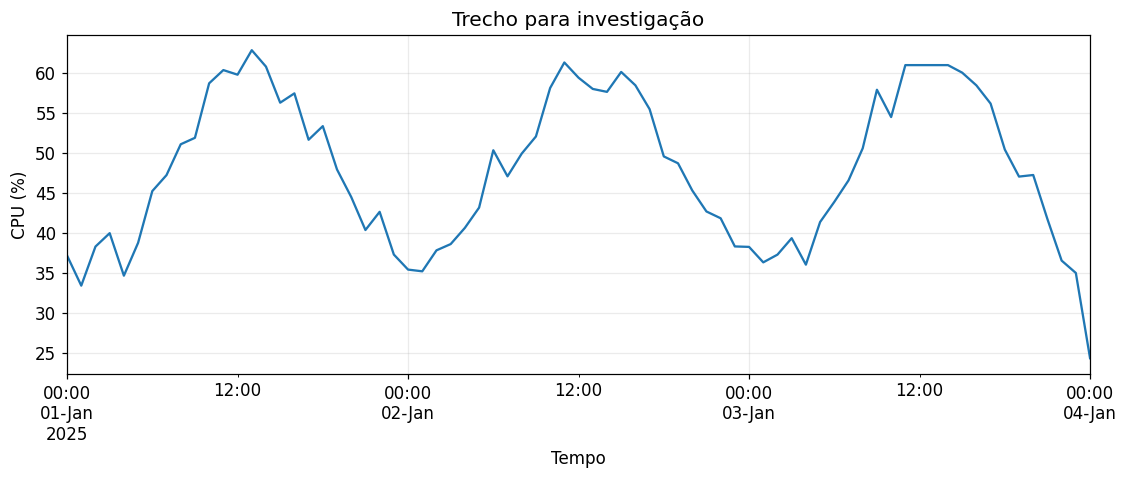

In [36]:
# Exercício: inspeção de um intervalo específico.
inicio = treino.index[0]
fim = inicio + pd.Timedelta(days=3)
trecho = treino.loc[inicio:fim]
print('Quantidade de leituras:', len(trecho))
trecho.plot(title='Trecho para investigação', ylabel='CPU (%)', xlabel='Tempo')
plt.show()
# Acrescentar aqui as alterações e interpretações dos exercícios.

## 40. Respostas orientadoras para os primeiros exercícios

**Exercício 1.** A variável é CPU média horária em porcentagem. A frequência é uma hora e o horizonte é 24 horas. Na emissão em bloco, nenhuma medição interna do dia futuro é conhecida. Na atualização horária, novas medições podem entrar em cada previsão seguinte, caracterizando outra tarefa.

**Exercício 3.** O limite de três horas impede preencher integralmente uma lacuna de 12 horas. A interrupção evita uma decisão silenciosa. Uma política possível é suspender previsões quando a qualidade do histórico não atende ao requisito, ou utilizar um procedimento específico validado para falhas longas. A escolha depende da dinâmica e do risco operacional.

**Exercício 4.** Com amostras a cada seis horas, um dia contém quatro amostras e uma semana contém 28. Não manter os períodos 24 e 168, pois eles passariam a representar seis e 42 dias. A agregação reduz a resolução e pode esconder picos.

**Exercício 6.** A vantagem da referência semanal pode diminuir quando não há diferença entre dias úteis e fins de semana. Ela ainda pode capturar o padrão diário, porque 168 é múltiplo de 24, mas utiliza informação mais antiga.

**Exercício 11.** O limite ideal de Nyquist é metade da taxa de amostragem. Com 10 amostras por segundo, componentes acima de 5 Hz podem aparecer em frequências incorretas se não houver filtragem adequada. A coleta precisa considerar o fenômeno antes da redução de dados.

## 41. Glossário

| Termo | Significado no material |
|---|---|
| Frequência de coleta | Intervalo ou taxa com que as medições são obtidas |
| Horizonte | Distância entre emissão e instante previsto |
| Sazonalidade | Repetição associada a um período reconhecível |
| Tendência | Alteração persistente do nível |
| Lag ou defasagem | Valor associado a um instante anterior |
| Imputação | Substituição de uma ausência por um valor estimado |
| Vazamento de dados | Uso de informação que não estaria disponível na tarefa avaliada |
| Treinamento | Dados usados para ajustar parâmetros |
| Validação | Dados utilizados para comparar e selecionar candidatos |
| Teste | Período reservado para avaliação após a escolha |
| Origem da previsão | Instante em que uma previsão é emitida |
| Previsão recursiva | Uso de previsões intermediárias para prever passos seguintes |
| Resíduo | Diferença associada ao ajuste do modelo nos dados usados |
| Erro fora da amostra | Diferença em uma previsão avaliada posteriormente |
| Cobertura | Proporção de observações contidas nos intervalos |
| Mudança de regime | Alteração relevante no processo que produz os dados |
| Aliasing | Representação incorreta de frequências por amostragem insuficiente |

## 42. Referências e documentação

HYNDMAN, R. J.; ATHANASOPOULOS, G. *Forecasting: Principles and Practice*. 3. ed. Melbourne: OTexts, 2021. Disponível em: https://otexts.com/fpp3/ . Referência para fundamentos, validação temporal, referências simples e avaliação.

PANDAS. *User Guide: Time series / date functionality*. Disponível em: https://pandas.pydata.org/docs/user_guide/timeseries.html . Documentação de datas, fusos, frequência e agregação.

STATSMODELS. *Time Series Analysis*. Disponível em: https://www.statsmodels.org/stable/tsa.html . Documentação dos modelos e diagnósticos usados.

STATSMODELS. *Stationarity and detrending (ADF/KPSS)*. Disponível em: https://www.statsmodels.org/stable/examples/notebooks/generated/stationarity_detrending_adf_kpss.html . Hipóteses e exemplos dos testes.

SCIKIT-LEARN. *TimeSeriesSplit*. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html . Divisão cronológica para validação.

SCIKIT-LEARN. *Common pitfalls and recommended practices*. Disponível em: https://scikit-learn.org/stable/common_pitfalls.html . Cuidados com vazamento e preparação.

NUMPY. *Discrete Fourier Transform*. Disponível em: https://numpy.org/doc/stable/reference/routines.fft.html . Operações de Fourier do exemplo de sensores.

Consulta da documentação de séries temporais e validação temporal: 9 out. 2026. As versões instaladas estão registradas na seção de ambiente. Os códigos e dados sintéticos deste notebook foram elaborados para fins didáticos.

**Avisos observados na execução verificada.** A versão utilizada de statsmodels informa uma mudança futura no retorno de `adfuller`; nesta execução, o retorno em tupla é válido. Nos modelos ARIMA e SARIMA, alguns parâmetros iniciais propostos são substituídos por zeros para iniciar a otimização. Esses avisos sobre inicialização diferem de falha de convergência. As funções verificam a indicação de convergência do ajuste e emitem um aviso específico se ela falhar. Não foram observadas falhas de convergência nesta execução. O ambiente de execução ficou registrado na segunda célula de código.